# Scikit-learn vs Spark MLlib: tebak negara asal novel

Satu data, satu tugas, dua kerangka. Notebook ini melatih tiga jenis model di scikit-learn dan tiga jenis yang sama di Spark MLlib, lalu membandingkan keduanya dari sisi akurasi dan kecepatan, sebelum dan sesudah tuning.

**Tugasnya.** Dari korpus teks (judul, sinopsis, tag), genre, tipe novel, dan beberapa kolom angka, tebak `type_origin`: CN, JP, atau KR. Tugas ini dipilih karena labelnya tersedia dan bersih untuk hampir 39 ribu novel, kelasnya tiga (bukan biner), dan fiturnya campuran: teks berdimensi puluhan ribu bersama beberapa kolom kecil. Kombinasi itu cukup berat untuk memperlihatkan beda kedua kerangka.

**Pasangan modelnya.**

| Algoritma | scikit-learn | Spark MLlib |
|---|---|---|
| Logistic Regression | A | D |
| Naive Bayes (multinomial) | B | E |
| Random Forest | C | F |

**Alurnya.**

1. Setup dan memuat data
2. EDA singkat (hanya yang memengaruhi keputusan modeling)
3. Konfigurasi: split, fold, preprocessing di kedua kerangka
4. Feature selection (ANOVA F) dan pemilihan jumlah fitur
5. Model A, B, C (scikit-learn), Evaluasi 1
6. Model D, E, F (MLlib), Evaluasi 2
7. Komparasi Evaluasi 1 vs 2
8. Tuning A, B, C, Evaluasi 3
9. Tuning D, E, F, Evaluasi 4
10. Komparasi Evaluasi 3 vs 4
11. Komparasi keseluruhan: kecepatan, performa, skala data

**Cara pakai.** Buka di JupyterLab container `notebook` (<http://localhost:8888>), pilih Run All. Dua hal yang perlu dicek dulu:

- Worker Spark hanya punya 2 core. Tutup kernel notebook lain yang sedang memegang sesi Spark (`eda_visualisasi`, `check`), kalau tidak sesi di sini akan menunggu core tanpa pesan error.
- Untuk uji cepat (sekitar 6 ribu baris), jalankan kernel dengan environment `NB_SMOKE=1`. Hasil mode ini hanya untuk memastikan kode jalan, jangan dibaca sebagai hasil.
- Run penuh memakan sekitar 20 menit (run 14 Oktober 2026: 19,4 menit) di cluster 2 core. Hasilnya juga tersimpan di `Doc/generated/sklearn_vs_mllib.json`, jadi laporan tidak perlu menjalankan ulang.

## 1. Setup

Semua import, konfigurasi, dan fungsi bantu ada di satu sel supaya bagian bawah tinggal membaca alur. Dua kerangka diberi jatah yang sama: 2 core. Palet dua warna dipakai konsisten, biru untuk scikit-learn dan oranye untuk MLlib.

In [1]:
import os, time, json, warnings
from contextlib import contextmanager
from functools import reduce
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import sparse

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, PredefinedSplit, StratifiedKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder

from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression as SparkLR
from pyspark.ml.classification import NaiveBayes as SparkNB
from pyspark.ml.classification import RandomForestClassifier as SparkRF
from pyspark.ml.evaluation import Evaluator
from pyspark.ml.feature import (
    IDF, CountVectorizerModel, Imputer, NGram, Normalizer, QuantileDiscretizer, RegexTokenizer,
    SQLTransformer, StringIndexer, UnivariateFeatureSelector, VectorAssembler,
)
from pyspark.ml.feature import CountVectorizer as SparkCountVectorizer
from pyspark.ml.feature import OneHotEncoder as SparkOneHotEncoder
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.sql import functions as F

from src.common.config import get_settings
from src.common.spark_session import build_spark_session

warnings.filterwarnings("ignore")

SMOKE = os.environ.get("NB_SMOKE", "0") == "1"
SEED = 42
CORES = 2
CLASSES = ["CN", "JP", "KR"]
SK_COLOR, ML_COLOR = "#2a78d6", "#eb6834"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 10,
})


@contextmanager
def stopwatch():
    box = {}
    start = time.perf_counter()
    yield box
    box["s"] = time.perf_counter() - start


def metrics(y_true, y_pred):
    per_class = f1_score(y_true, y_pred, average=None, labels=[0, 1, 2])
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted"),
        **{f"f1_{c}": v for c, v in zip(CLASSES, per_class)},
    }


RESULTS, PRED, TIMING, TUNING_LOG = [], {}, {}, []


def iterations(model):
    """Iterasi L-BFGS yang benar-benar dijalankan; kriteria berhenti kedua kerangka berbeda, jadi waktu harus dibaca bersama angka ini."""
    n = getattr(model, "n_iter_", None)
    if n is not None:
        return int(np.max(n))
    return int(model.summary.totalIterations)


def record(stage, framework, label, algo, fit_s, predict_s, y_true, y_pred, **extra):
    row = dict(stage=stage, framework=framework, model=label, algo=algo,
               fit_s=fit_s, predict_s=predict_s, **metrics(y_true, y_pred), **extra)
    RESULTS.append(row)
    PRED[(stage, label)] = (np.asarray(y_true), np.asarray(y_pred))
    return row


print(f"Mode uji cepat: {SMOKE} | seed {SEED} | jatah core per kerangka: {CORES}")

Mode uji cepat: False | seed 42 | jatah core per kerangka: 2


In [2]:
spark = build_spark_session(
    "sklearn-vs-mllib",
    extra_conf={"spark.cores.max": str(CORES), "spark.executor.memory": "2g"},
)
spark.sparkContext.setLogLevel("ERROR")
settings = get_settings()
# Checkpoint ke MinIO: blok localCheckpoint ikut hilang kalau executor mati (misalnya kehabisan memori).
spark.sparkContext.setCheckpointDir(
    settings.minio.s3a_uri(settings.minio.bucket_curated, "checkpoints/sklearn_vs_mllib"))
print("Spark", spark.version, "| master", spark.sparkContext.master,
      "| paralelisme default", spark.sparkContext.defaultParallelism)

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/certs/truststore.p12 -Djavax.net.ssl.trustStorePassword=changeit -Djavax.net.ssl.trustStoreType=PKCS12


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/certs/truststore.p12 -Djavax.net.ssl.trustStorePassword=changeit -Djavax.net.ssl.trustStoreType=PKCS12


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/14 08:13:44 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


2026-10-14 08:13:45 | INFO     | src.common.spark_session | SparkSession aktif | app=sklearn-vs-mllib | master=spark://spark-master:7077 | versi=3.5.3


Spark 3.5.3 | master spark://spark-master:7077 | paralelisme default 2


## 2. Dataset

Sumbernya `novels_clean` dari Fase 2 (zona clean di MinIO). Yang diambil: baris dengan sinyal teks dan `type_origin` bernilai CN, JP, atau KR. Negara lain (FIL, ID, TH, dan seterusnya) hanya puluhan baris per negara, terlalu sedikit untuk dipisah dan hanya mengacaukan evaluasi per kelas.

Satu keputusan yang perlu dijelaskan: kata penunjuk negara (`china`, `chinese`, `korea`, `korean`, `japan`, `japanese`) dibuang dari teks. Tanpa itu, tag seperti "ancient china" membuat sebagian tebakan hanya soal mencocokkan kata, dan skor menjadi terlalu bagus untuk alasan yang kurang menarik. Penanda budaya yang lebih halus (genre Xianxia, misalnya) sengaja dibiarkan karena itu sinyal yang sah.

Pembersihan ini dikerjakan Spark, lalu hasilnya ditarik ke pandas untuk jalur scikit-learn. Jalur MLlib tetap membaca dari DataFrame Spark yang sama.

In [3]:
settings = get_settings()
clean = spark.read.parquet(settings.minio.s3a_uri(settings.minio.bucket_clean, "novels_clean"))

COUNTRY_WORDS = r"\b(china|chinese|korea|korean|japan|japanese)\b"
raw = (
    clean.filter(F.col("has_text_signal") & F.col("type_origin").isin(*CLASSES))
    .select("series_id", "corpus_clean", "genre_list", "type_origin", "type",
            "chapter_count", "year", "days_per_chapter", "n_tags", "is_completed")
    .withColumn("corpus_clean", F.regexp_replace("corpus_clean", COUNTRY_WORDS, " "))
    .withColumn("type", F.coalesce("type", F.lit("UNKNOWN")))
    .withColumn("year_missing", F.col("year").isNull().cast("double"))
    .withColumn("chapters_missing", F.col("chapter_count").isNull().cast("double"))
)

with stopwatch() as t_load:
    pdf = raw.toPandas()
pdf["genre_list"] = pdf["genre_list"].apply(list)
pdf = pdf.sort_values("series_id", kind="mergesort").reset_index(drop=True)

if SMOKE:
    _, keep = train_test_split(np.arange(len(pdf)), test_size=6000, stratify=pdf["type_origin"], random_state=SEED)
    pdf = pdf.iloc[np.sort(keep)].reset_index(drop=True)

print(f"{len(pdf):,} novel | {pdf.shape[1]} kolom | tarik ke pandas {t_load['s']:.1f} dtk")
preview = pdf.assign(corpus_clean=pdf["corpus_clean"].str.slice(0, 70) + "...").head(4)
display(preview.drop(columns=["year_missing", "chapters_missing"]))

38,983 novel | 12 kolom | tarik ke pandas 3.3 dtk


,series_id,corpus_clean,genre_list,type_origin,type,chapter_count,year,days_per_chapter,n_tags,is_completed
0,5,coiling dragon empires rise fall yulan contine...,"[Action, Adventure, Fantasy, Seinen, Xuanhuan]",CN,Web Novel,806.0,2008.0,3949.0,51,0
1,10,martial god asura one night mysterious unexpla...,"[Action, Adventure, Drama, Harem, Mature, Smut...",CN,Web Novel,6573.0,2013.0,1051.7,56,0
2,14,gods mythical abode mountain cloud end cliff d...,"[Action, Adventure, Ecchi, Fantasy, Harem, Mar...",CN,Web Novel,2200.0,2014.0,545.9,57,0
3,15,shall seal heavens want heavens shall lack wan...,"[Action, Adventure, Drama, Xianxia]",CN,Web Novel,1613.0,2014.0,719.5,57,1


## 3. EDA singkat

Cuma tiga pertanyaan yang menentukan keputusan di bagian berikutnya: seberapa timpang kelasnya, apakah kolom yang kosong ikut membawa informasi, dan genre mana yang memisahkan negara. EDA lengkap katalog ada di `eda_visualisasi.ipynb`.

,jumlah,persen
type_origin,,
CN,23685,60.8
JP,6751,17.3
KR,8547,21.9


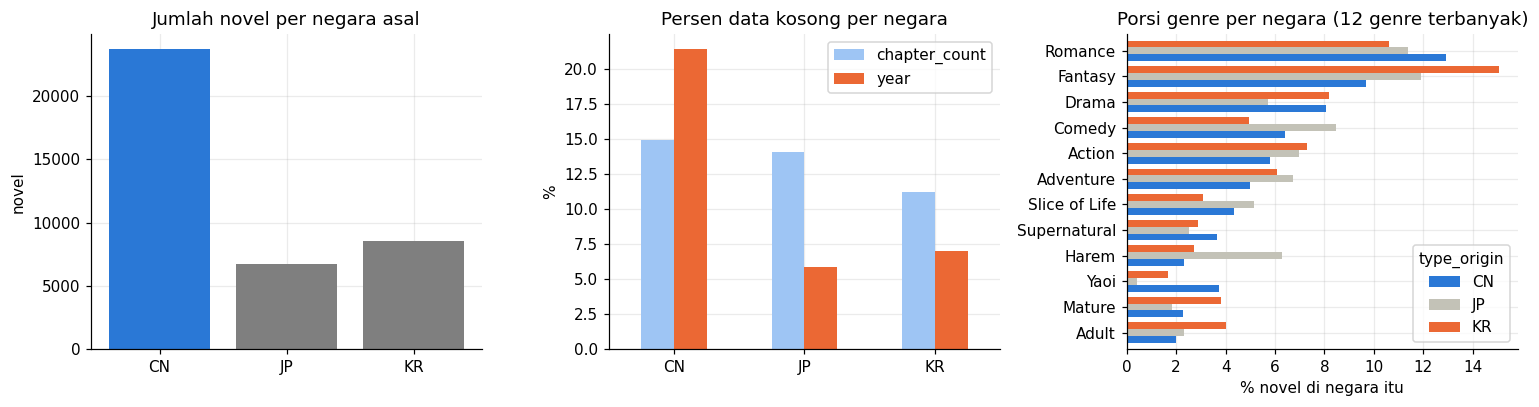

Median panjang korpus (kata): {'CN': 120.0, 'JP': 92.0, 'KR': 89.0}


In [4]:
counts = pdf["type_origin"].value_counts().reindex(CLASSES)
share = (counts / counts.sum() * 100).round(1)
display(pd.DataFrame({"jumlah": counts, "persen": share}))

miss = (pdf.assign(chapter_count=pdf["chapter_count"].isna(), year=pdf["year"].isna())
        .groupby("type_origin")[["chapter_count", "year"]].mean().mul(100).reindex(CLASSES))

top_genres = pdf["genre_list"].explode().value_counts().head(12).index
exploded = pdf[["type_origin", "genre_list"]].explode("genre_list")
genre_share = (pd.crosstab(exploded["genre_list"], exploded["type_origin"], normalize="columns")
               .mul(100).reindex(top_genres)[CLASSES])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].bar(CLASSES, counts.values, color=[SK_COLOR, "#7f7f7f", "#7f7f7f"])
axes[0].set_title("Jumlah novel per negara asal")
axes[0].set_ylabel("novel")

miss.plot.bar(ax=axes[1], color=["#9ec5f4", "#eb6834"], rot=0)
axes[1].set_title("Persen data kosong per negara")
axes[1].set_xlabel("")
axes[1].set_ylabel("%")

genre_share.iloc[::-1].plot.barh(ax=axes[2], color=[SK_COLOR, "#c3c2b7", "#eb6834"], width=0.8)
axes[2].set_title("Porsi genre per negara (12 genre terbanyak)")
axes[2].set_xlabel("% novel di negara itu")
axes[2].set_ylabel("")
plt.tight_layout()
plt.show()

words = pdf["corpus_clean"].str.count(" ") + 1
print("Median panjang korpus (kata):", words.groupby(pdf["type_origin"]).median().reindex(CLASSES).to_dict())

Tiga hal yang kelihatan dari grafik di atas dan dipakai di bawah:

- **Kelasnya timpang.** CN jauh lebih banyak dari JP dan KR. Karena itu metrik utama notebook ini macro-F1 (rata-rata F1 per kelas), bukan akurasi. Akurasi tetap dilaporkan, tapi model yang asal menebak CN sudah terlihat lumayan di akurasi.
- **Kosongnya data tidak acak.** Tahun terbit paling sering kosong di novel CN. Fakta bahwa sebuah kolom kosong ikut menjadi sinyal, jadi bagian preprocessing menambahkan penanda `year_missing` dan `chapters_missing` setelah nilainya diisi median.
- **Genre membantu tapi tidak cukup.** Xianxia, Xuanhuan, dan Yaoi hampir milik CN, sedangkan Harem, School Life, dan Ecchi lebih sering muncul di JP. Sebagian besar genre lain tersebar rata, jadi teks tetap harus bekerja.

## 4. Konfigurasi: split, fold, preprocessing

**Split.** Data diurutkan menurut `series_id` supaya tidak bergantung pada urutan baris hasil Spark, lalu dipecah 80% latih dan 20% uji, berstrata menurut negara, seed 42. Set uji disentuh sekali per evaluasi dan tidak pernah dipakai untuk memilih apa pun.

**Fold.** Bagian latih dibagi lagi menjadi 3 fold berstrata. Nomor fold disimpan sebagai kolom dan dikirim ke kedua kerangka, jadi cross-validation di scikit-learn (`PredefinedSplit`) dan di MLlib (`foldCol`) memakai potongan data yang persis sama.

**Preprocessing.** Kedua kerangka membangun jenis fitur yang sama:

| Blok | scikit-learn | Spark MLlib |
|---|---|---|
| Teks | `TfidfVectorizer`, 1-2 gram, 20 ribu fitur, min_df 5, max_df 0,9 | `RegexTokenizer` + `NGram` + `CountVectorizer` + `IDF` + `Normalizer`, setelan sama |
| Genre | multi-hot (`CountVectorizer`, binary) | multi-hot (`CountVectorizer`, binary) |
| Tipe novel | `OneHotEncoder` | `StringIndexer` + `OneHotEncoder` |
| Angka (bab, tahun, hari per bab, jumlah tag) | isi median, 5 bin kuantil, one-hot | `Imputer` median, `QuantileDiscretizer` 5 bucket, one-hot |
| Penanda | `year_missing`, `chapters_missing`, `is_completed` | sama |

Semua fitur akhirnya non-negatif, syarat Naive Bayes multinomial. Dua selisih kecil sengaja tidak ditambal: rumus IDF scikit-learn memakai smoothing `+1` yang tidak ada di Spark, dan binning kuantil Spark bersifat aproksimasi. Dimensi akhir kedua sisi dicetak di bawah supaya selisihnya terlihat.

In [5]:
pdf["y"] = pdf["type_origin"].map({c: i for i, c in enumerate(CLASSES)}).astype(int)

tr_pos, te_pos = train_test_split(np.arange(len(pdf)), test_size=0.2, random_state=SEED, stratify=pdf["y"])
pdf["split"] = "train"
pdf.loc[te_pos, "split"] = "test"
pdf["fold"] = -1

train_part = pdf[pdf["split"] == "train"]
for fold_no, (_, valid_pos) in enumerate(StratifiedKFold(3, shuffle=True, random_state=SEED).split(train_part, train_part["y"])):
    pdf.loc[train_part.index[valid_pos], "fold"] = fold_no

pdf_tr = pdf[pdf["split"] == "train"].reset_index(drop=True)
pdf_te = pdf[pdf["split"] == "test"].reset_index(drop=True)
y_tr, y_te, fold_tr = pdf_tr["y"].to_numpy(), pdf_te["y"].to_numpy(), pdf_tr["fold"].to_numpy()

display(pd.DataFrame({
    "latih": pdf_tr["type_origin"].value_counts().reindex(CLASSES),
    "uji": pdf_te["type_origin"].value_counts().reindex(CLASSES),
    **{f"fold {i}": pdf_tr[pdf_tr["fold"] == i]["type_origin"].value_counts().reindex(CLASSES) for i in range(3)},
}))

,latih,uji,fold 0,fold 1,fold 2
type_origin,,,,,
CN,18948,4737,6316,6316,6316
JP,5401,1350,1801,1800,1800
KR,6837,1710,2279,2279,2279


In [6]:
def identity(x):
    return x


NUM_COLS = ["chapter_count", "year", "days_per_chapter", "n_tags"]
FLAG_COLS = ["year_missing", "chapters_missing", "is_completed"]

sk_prep = ColumnTransformer([
    ("text", TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), max_features=20000, min_df=5, max_df=0.9), "corpus_clean"),
    ("genre", CountVectorizer(analyzer=identity, binary=True, lowercase=False), "genre_list"),
    ("type", OneHotEncoder(handle_unknown="ignore"), ["type"]),
    ("num", make_pipeline(SimpleImputer(strategy="median"),
                          KBinsDiscretizer(n_bins=5, encode="onehot", strategy="quantile", subsample=None)), NUM_COLS),
    ("flag", "passthrough", FLAG_COLS),
], sparse_threshold=1.0)

with stopwatch() as t_sk_prep:
    Xtr = sparse.csr_matrix(sk_prep.fit_transform(pdf_tr))
    Xte = sparse.csr_matrix(sk_prep.transform(pdf_te))
TIMING["prep_sk"] = t_sk_prep["s"]
sk_names = sk_prep.get_feature_names_out()
print(f"scikit-learn: latih {Xtr.shape}, uji {Xte.shape}, siap dalam {TIMING['prep_sk']:.1f} dtk")

scikit-learn: latih (31186, 20061), uji (7797, 20061), siap dalam 10.3 dtk


In [7]:
def spark_stages():
    num_d = [c + "_d" for c in NUM_COLS]
    num_i = [c + "_i" for c in NUM_COLS]
    num_b = [c + "_b" for c in NUM_COLS]
    num_oh = [c + "_oh" for c in NUM_COLS]
    cast_sql = ", ".join(f"CAST({c} AS DOUBLE) AS {c}_d" for c in NUM_COLS)
    return [
        RegexTokenizer(inputCol="corpus_clean", outputCol="words", pattern=r"\s+"),
        NGram(n=2, inputCol="words", outputCol="bigrams"),
        SQLTransformer(statement="SELECT *, concat(words, bigrams) AS terms FROM __THIS__"),
        SparkCountVectorizer(inputCol="terms", outputCol="tf", vocabSize=20000, minDF=5, maxDF=0.9),
        IDF(inputCol="tf", outputCol="tfidf"),
        Normalizer(inputCol="tfidf", outputCol="text_vec", p=2.0),
        SparkCountVectorizer(inputCol="genre_list", outputCol="genre_vec", binary=True),
        StringIndexer(inputCol="type", outputCol="type_idx", handleInvalid="keep"),
        SparkOneHotEncoder(inputCol="type_idx", outputCol="type_vec", dropLast=False, handleInvalid="keep"),
        SQLTransformer(statement=f"SELECT *, {cast_sql} FROM __THIS__"),
        Imputer(inputCols=num_d, outputCols=num_i, strategy="median"),
        QuantileDiscretizer(inputCols=num_i, outputCols=num_b, numBuckets=5, handleInvalid="keep"),
        SparkOneHotEncoder(inputCols=num_b, outputCols=num_oh, dropLast=False, handleInvalid="keep"),
        VectorAssembler(inputCols=["text_vec", "genre_vec", "type_vec", *num_oh, *FLAG_COLS], outputCol="features_all"),
        StringIndexer(inputCol="type_origin", outputCol="label", stringOrderType="alphabetAsc"),
    ]


ids_sdf = spark.createDataFrame(pdf[["series_id", "split", "fold"]]).withColumn("fold", F.col("fold").cast("int"))
# Satu partisi per core: job MLlib di sini terikat overhead per tugas, dan 2 partisi 24% lebih cepat dari 4.
spark_data = raw.join(ids_sdf, "series_id").repartition(CORES, "series_id").cache()
spark_data.count()

with stopwatch() as t_sp_prep:
    prep_model = Pipeline(stages=spark_stages()).fit(spark_data.filter("split = 'train'"))
    # Checkpoint memotong lineage panjang pipeline fitur, kalau tidak setiap job menyiarkan rencana besar.
    feat = (prep_model.transform(spark_data)
            .select("series_id", "split", "fold", "label", "features_all")
            .checkpoint())
    train_sdf = feat.filter("split = 'train'").cache()
    test_sdf = feat.filter("split = 'test'").cache()
    n_tr_sp, n_te_sp = train_sdf.count(), test_sdf.count()
TIMING["prep_ml"] = t_sp_prep["s"]

dim_sp = train_sdf.first()["features_all"].size
assert (n_tr_sp, n_te_sp) == (len(pdf_tr), len(pdf_te)), "split Spark dan pandas tidak sama"
print(f"Spark MLlib : latih ({n_tr_sp}, {dim_sp}), uji ({n_te_sp}, {dim_sp}), siap dalam {TIMING['prep_ml']:.1f} dtk")
print(f"Selisih dimensi dengan scikit-learn: {dim_sp - Xtr.shape[1]:+d} kolom")

cv_models = [s for s in prep_model.stages if isinstance(s, CountVectorizerModel)]
sp_names = ([f"text__{t}" for t in cv_models[0].vocabulary] + [f"genre__{g}" for g in cv_models[1].vocabulary])

Spark MLlib : latih (31186, 20067), uji (7797, 20067), siap dalam 28.1 dtk
Selisih dimensi dengan scikit-learn: +6 kolom


## 5. Feature selection

Matriks fitur punya sekitar dua puluh ribu kolom, hampir semuanya potongan teks yang muncul di segelintir novel. Memilih kolom yang benar-benar membedakan negara punya dua manfaat yang bisa diukur: model lebih cepat dilatih, dan (kadang) lebih sedikit noise.

Metodenya ANOVA F, satu uji untuk tiap fitur: seberapa jauh rata-rata fitur itu berbeda antar-kelas dibanding sebarannya di dalam kelas. Ini filter univariat, jadi murah dan tidak bergantung pada model. Di scikit-learn dipakai `f_classif`, di MLlib `UnivariateFeatureSelector` (jenis fitur continuous, jenis label categorical, yang secara internal juga ANOVA F).

Ada tiga pertanyaan:

1. Kedua kerangka memilih fitur yang sama atau tidak?
2. Blok fitur mana yang bertahan?
3. Berapa fitur yang dipertahankan? Ini dijawab dengan kurva: model Logistic Regression dilatih pada fold 1 dan 2, diuji pada fold 0, untuk beberapa nilai k. Set uji tidak ikut campur.

Random Forest mendapat kurva dan `k` sendiri, dengan dua alasan yang terukur. Pertama, hutan acak memilih √k fitur di tiap percabangan, jadi ribuan potongan teks yang jarang muncul hanya menambah noise: pada uji awal, Random Forest scikit-learn mencapai macro-F1 0,795 di 1.000 fitur tetapi 0,722 di 10.000 fitur. Kedua, MLlib menyimpan setiap baris latih sebagai larik bin sepanjang `k` (memori kira-kira baris × k × 4 byte). Pada 31 ribu baris dan 10.000 fitur itu sekitar 1,2 GB, dan executor 2 GB kehabisan memori. Karena itu kurva Random Forest berhenti di 3.000 fitur. Pasangan C dan F tetap memakai `k` yang sama, jadi perbandingan antar-kerangka tetap adil.

In [8]:
def anova_rank(X, y):
    scores, _ = f_classif(X, y)
    scores = np.nan_to_num(scores, nan=0.0)
    return np.argsort(-scores, kind="stable"), scores


def spark_selector(k):
    return (UnivariateFeatureSelector(featuresCol="features_all", outputCol="features", labelCol="label",
                                      selectionMode="numTopFeatures")
            .setFeatureType("continuous").setLabelType("categorical").setSelectionThreshold(float(k)))


def spark_view(df, selector_model=None):
    if selector_model is None:
        return df.select("series_id", "fold", "label", F.col("features_all").alias("features"))
    return selector_model.transform(df).select("series_id", "fold", "label", "features")


with stopwatch() as t_rank:
    rank_full, scores_full = anova_rank(Xtr, y_tr)
TIMING["rank_sk"] = t_rank["s"]

top = pd.DataFrame({
    "fitur": sk_names[rank_full[:15]],
    "F": scores_full[rank_full[:15]].round(0),
})
top["blok"] = top["fitur"].str.split("__").str[0]
display(top)

K_REF = min(3000, dim_sp, Xtr.shape[1])
sp_ref = spark_selector(K_REF).fit(train_sdf)
named = len(sp_names)
sk_set = {n for n in sk_names[rank_full[:K_REF]] if n.startswith(("text__", "genre__"))}
sp_set = {sp_names[i] for i in sp_ref.selectedFeatures if i < named}
overlap = len(sk_set & sp_set) / max(1, min(len(sk_set), len(sp_set)))
print(f"\nTop-{K_REF}: {len(sk_set & sp_set)} dari {min(len(sk_set), len(sp_set))} fitur teks/genre dipilih oleh kedua kerangka ({overlap:.1%})")

blocks = pd.Series(sk_names).str.split("__").str[0]
chosen = blocks.iloc[np.sort(rank_full[:K_REF])].value_counts()
comp = pd.DataFrame({"total": blocks.value_counts(), f"bertahan di top-{K_REF}": chosen}).fillna(0).astype(int)
comp["persen bertahan"] = (comp.iloc[:, 1] / comp["total"] * 100).round(1)
display(comp)

,fitur,F,blok
0,text__adapted manga,5639.0,text
1,text__manga,4311.0,text
2,type__type_Light Novel,3927.0,type
3,text__adapted manhwa,2991.0,text
4,text__manhwa,2989.0,text
5,text__european ambience,2872.0,text
6,text__ambience,2871.0,text
7,text__european,2829.0,text
8,type__type_Web Novel,2427.0,type
9,num__chapter_count_0.0,1577.0,num



Top-3000: 2958 dari 2977 fitur teks/genre dipilih oleh kedua kerangka (99.4%)


,total,bertahan di top-3000,persen bertahan
flag,3,3,100.0
genre,35,34,97.1
num,20,18,90.0
text,20000,2943,14.7
type,3,2,66.7


Tabel pertama memperlihatkan fitur dengan skor F tertinggi, dan blok mana yang menyumbangnya. Tabel kedua memperlihatkan blok mana yang paling banyak bertahan. Kolom kecil seperti tipe novel dan penanda kosong hampir selalu lolos karena jumlahnya sedikit tapi informatif, sedangkan sebagian besar kolom teks yang jarang muncul tersaring.

Sekarang kurvanya. Untuk tiap k dicatat macro-F1 di fold 0, waktu latih, dan jumlah iterasi Logistic Regression di kedua kerangka, ditambah macro-F1 Random Forest scikit-learn untuk memilih `k` Random Forest.

k=  300 | sklearn F1 0.8801 (0.9s, 131 iter) | MLlib F1 0.8160 (4.1s, 40 iter)


k= 1000 | sklearn F1 0.9100 (1.3s, 141 iter) | MLlib F1 0.8861 (7.8s, 101 iter)


k= 3000 | sklearn F1 0.9235 (1.6s, 119 iter) | MLlib F1 0.9238 (11.9s, 133 iter)


k= 5000 | sklearn F1 0.9299 (1.9s, 127 iter) | MLlib F1 0.9286 (13.7s, 145 iter)


k=10000 | sklearn F1 0.9305 (2.4s, 129 iter) | MLlib F1 0.9293 (21.7s, 200 iter)


k=  all | sklearn F1 0.9318 (3.0s, 124 iter) | MLlib F1 0.9310 (19.4s, 200 iter)


Random Forest k=  100 | sklearn F1 0.8157 (2.1s)


Random Forest k=  300 | sklearn F1 0.8165 (2.4s)


Random Forest k= 1000 | sklearn F1 0.7943 (2.8s)


Random Forest k= 3000 | sklearn F1 0.7738 (2.9s)


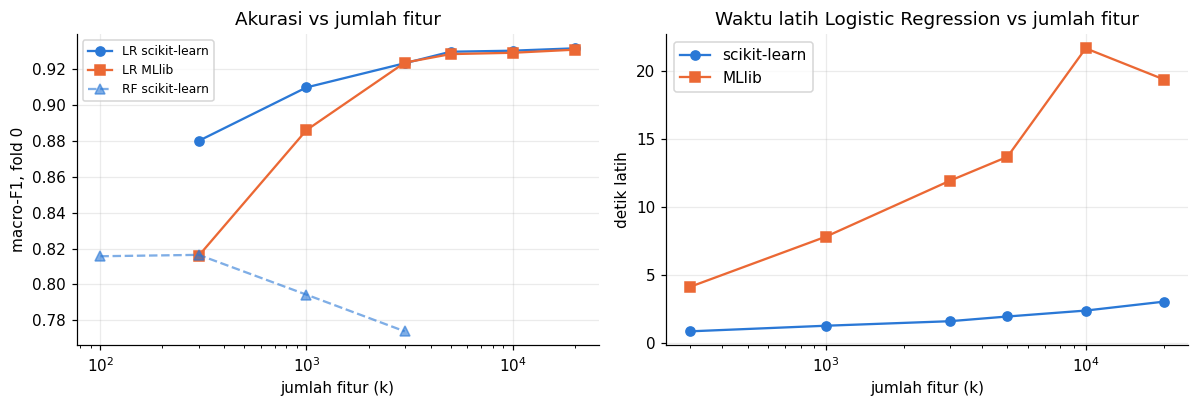

In [9]:
K_CURVE = [k for k in (300, 1000, 3000, 5000, 10000) if k < Xtr.shape[1] and k < dim_sp] + ["all"]
K_CURVE_RF = [k for k in (100, 300, 1000, 3000) if k < Xtr.shape[1]]
fit_mask = fold_tr != 0
rank_fold, _ = anova_rank(Xtr[fit_mask], y_tr[fit_mask])

fit_df = train_sdf.filter("fold != 0")
val_df = train_sdf.filter("fold = 0")
n_fit_rows = int(fit_mask.sum())
rows = []
for k in K_CURVE:
    cols = slice(None) if k == "all" else np.sort(rank_fold[:k])
    sk_model = LogisticRegression(C=1.0, max_iter=200)
    with stopwatch() as t_sk:
        sk_model.fit(Xtr[fit_mask][:, cols], y_tr[fit_mask])
    sk_f1 = f1_score(y_tr[~fit_mask], sk_model.predict(Xtr[~fit_mask][:, cols]), average="macro")

    sel = None if k == "all" else spark_selector(k).fit(fit_df)
    a, b = spark_view(fit_df, sel).cache(), spark_view(val_df, sel).cache()
    a.count(), b.count()
    with stopwatch() as t_ml:
        ml_model = SparkLR(family="multinomial", regParam=1.0 / n_fit_rows, maxIter=200, standardization=False).fit(a)
    got = ml_model.transform(b).select("label", "prediction").toPandas()
    ml_f1 = f1_score(got["label"].astype(int), got["prediction"].astype(int), average="macro")
    a.unpersist(), b.unpersist()

    rows.append(dict(k=k, sk_macro_f1=sk_f1, sk_fit_s=t_sk["s"], sk_iter=iterations(sk_model),
                     ml_macro_f1=ml_f1, ml_fit_s=t_ml["s"], ml_iter=iterations(ml_model)))
    print(f"k={k!s:>5} | sklearn F1 {sk_f1:.4f} ({t_sk['s']:.1f}s, {iterations(sk_model)} iter) | "
          f"MLlib F1 {ml_f1:.4f} ({t_ml['s']:.1f}s, {iterations(ml_model)} iter)")

curve = pd.DataFrame(rows)
curve["x"] = [Xtr.shape[1] if k == "all" else k for k in curve["k"]]

rf_rows = []
for k in K_CURVE_RF:
    cols = np.sort(rank_fold[:k])
    rf = RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=CORES, random_state=SEED)
    with stopwatch() as t_rf:
        rf.fit(Xtr[fit_mask][:, cols], y_tr[fit_mask])
    rf_f1 = f1_score(y_tr[~fit_mask], rf.predict(Xtr[~fit_mask][:, cols]), average="macro")
    rf_rows.append(dict(k=k, x=k, sk_macro_f1=rf_f1, sk_fit_s=t_rf["s"]))
    print(f"Random Forest k={k:>5} | sklearn F1 {rf_f1:.4f} ({t_rf['s']:.1f}s)")
curve_rf = pd.DataFrame(rf_rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(curve["x"], curve["sk_macro_f1"], "o-", color=SK_COLOR, label="LR scikit-learn")
axes[0].plot(curve["x"], curve["ml_macro_f1"], "s-", color=ML_COLOR, label="LR MLlib")
axes[0].plot(curve_rf["x"], curve_rf["sk_macro_f1"], "^--", color=SK_COLOR, alpha=0.6, label="RF scikit-learn")
axes[0].set_xscale("log"); axes[0].set_xlabel("jumlah fitur (k)"); axes[0].set_ylabel("macro-F1, fold 0")
axes[0].set_title("Akurasi vs jumlah fitur"); axes[0].legend(fontsize=8)
axes[1].plot(curve["x"], curve["sk_fit_s"], "o-", color=SK_COLOR, label="scikit-learn")
axes[1].plot(curve["x"], curve["ml_fit_s"], "s-", color=ML_COLOR, label="MLlib")
axes[1].set_xscale("log"); axes[1].set_xlabel("jumlah fitur (k)"); axes[1].set_ylabel("detik latih")
axes[1].set_title("Waktu latih Logistic Regression vs jumlah fitur"); axes[1].legend()
plt.tight_layout(); plt.show()

In [10]:
def pick_k(frame):
    """Fitur paling sedikit yang macro-F1-nya masih dalam 0,005 dari yang terbaik."""
    best = frame["sk_macro_f1"].max()
    return int(frame[frame["sk_macro_f1"] >= best - 0.005].sort_values("x").iloc[0]["x"])


k_star, K_RF = pick_k(curve), pick_k(curve_rf)
K2 = min(2 * k_star, Xtr.shape[1], dim_sp)
print(f"Logistic Regression dan Naive Bayes: k = {k_star} (macro-F1 terbaik di kurva {curve['sk_macro_f1'].max():.4f})")
print(f"Random Forest: k = {K_RF} (macro-F1 terbaik di kurvanya {curve_rf['sk_macro_f1'].max():.4f})")
print(f"Pada tuning nanti k Logistic Regression dan Naive Bayes dicoba di {sorted({k_star, K2})}")

SK_SETS, SPARK_SETS = {}, {}


def get_sk_sets(k):
    if k not in SK_SETS:
        cols = np.sort(rank_full[:k])
        SK_SETS[k] = (Xtr[:, cols], Xte[:, cols])
    return SK_SETS[k]


def get_spark_sets(k):
    if k not in SPARK_SETS:
        with stopwatch() as t:
            sel = spark_selector(k).fit(train_sdf)
        tr, te = spark_view(train_sdf, sel).cache(), spark_view(test_sdf, sel).cache()
        tr.count(), te.count()
        SPARK_SETS[k] = (sel, tr, te, t["s"])
    return SPARK_SETS[k]


with stopwatch() as t:
    for k in {k_star, K_RF}:
        get_sk_sets(k)
TIMING["select_sk"] = TIMING["rank_sk"] + t["s"]
TIMING["select_ml"] = sum(get_spark_sets(k)[3] for k in {k_star, K_RF})
print(f"Waktu seleksi: scikit-learn {TIMING['select_sk']:.1f} dtk, MLlib {TIMING['select_ml']:.1f} dtk")

Logistic Regression dan Naive Bayes: k = 5000 (macro-F1 terbaik di kurva 0.9318)
Random Forest: k = 100 (macro-F1 terbaik di kurvanya 0.8165)
Pada tuning nanti k Logistic Regression dan Naive Bayes dicoba di [5000, 10000]


Waktu seleksi: scikit-learn 0.2 dtk, MLlib 2.5 dtk


Aturan memilih k sengaja sederhana dan dibuat dari kurva scikit-learn saja: fitur paling sedikit yang skornya masih dalam 0,005 dari yang terbaik. Dengan aturan ini k tidak ikut "dioptimalkan sampai habis", dan kedua kerangka mulai dari jumlah fitur yang sama. Kalau kurva MLlib di atas ternyata puncaknya di tempat lain, itu catatan sendiri tapi tidak mengubah k, karena perbandingan model di bawah harus dimulai dari data yang sama persis.

Aturan yang sama dipakai dua kali: sekali pada kurva Logistic Regression (untuk model A, B, D, E) dan sekali pada kurva Random Forest (untuk model C dan F).

## 6. Model A, B, C: scikit-learn dengan setelan bawaan (Evaluasi 1)

Tiga model, semuanya dengan setelan yang masuk akal tanpa disetel apa-apa. Semuanya dilatih pada seluruh data latih dengan `k` fitur hasil seleksi, lalu dinilai sekali pada set uji.

| Model | Setelan | Alasan singkat |
|---|---|---|
| A. Logistic Regression | `C=1`, `max_iter=200` | Baseline linear untuk teks; cepat dan stabil. |
| B. Multinomial Naive Bayes | `alpha=1` | Paling murah, cocok untuk frekuensi/TF-IDF yang non-negatif. |
| C. Random Forest | 100 pohon, `max_depth=15`, `n_jobs=2`, `k` Random Forest | Wakil model berbasis pohon. Tidak ideal untuk fitur teks yang jarang (sparse), jadi hasilnya bagus untuk melihat ketimpangan. |

Waktu latih dan waktu prediksi dicatat terpisah, dan untuk Logistic Regression juga jumlah iterasinya. Metrik utama macro-F1; akurasi dan F1 per negara menyertainya.

A Logistic Regression  k=5000   macro-F1 0.9385 | latih 3.17 dtk | prediksi 0.00 dtk
B Naive Bayes          k=5000   macro-F1 0.8749 | latih 0.02 dtk | prediksi 0.00 dtk


C Random Forest        k=100    macro-F1 0.8119 | latih 3.54 dtk | prediksi 0.04 dtk

Evaluasi 1 (scikit-learn, bawaan, 31,186 latih / 7,797 uji)


,model,algo,k,accuracy,macro_f1,weighted_f1,f1_CN,f1_JP,f1_KR,fit_s,predict_s,iters
0,A,Logistic Regression,5000,0.9511,0.9385,0.9509,0.9693,0.9293,0.9169,3.1712,0.0027,150.0
1,B,Naive Bayes,5000,0.9020,0.8749,0.9016,0.9415,0.8549,0.8283,0.0170,0.0022,NaN
2,C,Random Forest,100,0.8553,0.8119,0.8482,0.9031,0.7923,0.7405,3.5421,0.0433,NaN


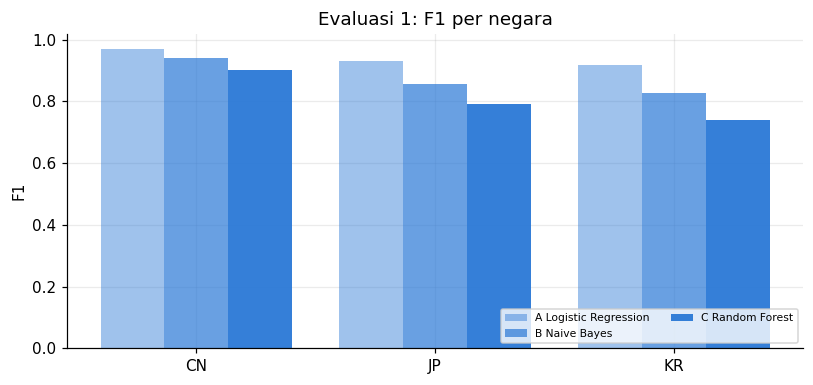

In [11]:
ALGO = {"A": "Logistic Regression", "B": "Naive Bayes", "C": "Random Forest",
        "D": "Logistic Regression", "E": "Naive Bayes", "F": "Random Forest"}
ORDER = ["Logistic Regression", "Naive Bayes", "Random Forest"]
SHOW = ["model", "algo", "k", "accuracy", "macro_f1", "weighted_f1", "f1_CN", "f1_JP", "f1_KR", "fit_s", "predict_s", "iters"]
K_OF = {"A": k_star, "B": k_star, "C": K_RF, "D": k_star, "E": k_star, "F": K_RF}
n_train = len(y_tr)


def lr_iters(label, model):
    return {"iters": iterations(model)} if ALGO[label] == "Logistic Regression" else {}


def fit_eval_sklearn(stage, label, estimator, Xa, ya, Xb, yb, **extra):
    with stopwatch() as tf:
        estimator.fit(Xa, ya)
    with stopwatch() as tp:
        pred = estimator.predict(Xb)
    return estimator, record(stage, "scikit-learn", label, ALGO[label], tf["s"], tp["s"], yb, pred,
                             **lr_iters(label, estimator), **extra)


def fit_eval_spark(stage, label, estimator, tr, te, **extra):
    with stopwatch() as tf:
        model = estimator.fit(tr)
    # Waktu prediksi MLlib sudah termasuk menarik hasil ke driver (toPandas).
    with stopwatch() as tp:
        out = model.transform(te).select("label", "prediction").toPandas()
    row = record(stage, "MLlib", label, ALGO[label], tf["s"], tp["s"],
                 out["label"].astype(int), out["prediction"].astype(int), **lr_iters(label, model), **extra)
    return model, row


def stage_frame(stage):
    return pd.DataFrame([r for r in RESULTS if r["stage"] == stage])


def show_stage(stage):
    frame = stage_frame(stage)
    display(frame[[c for c in SHOW if c in frame]].round(4).reset_index(drop=True))


def plot_perclass(stages, title):
    frame = pd.concat([stage_frame(s) for s in stages])
    fig, ax = plt.subplots(figsize=(7.5, 3.6))
    width = 0.8 / len(frame)
    for i, (_, r) in enumerate(frame.iterrows()):
        color = SK_COLOR if r["framework"] == "scikit-learn" else ML_COLOR
        ax.bar(np.arange(3) + i * width, [r[f"f1_{c}"] for c in CLASSES], width,
               color=color, alpha=0.45 + 0.5 * (i % 3) / 2, label=f"{r['model']} {r['algo']}")
    ax.set_xticks(np.arange(3) + 0.4 - width / 2, CLASSES)
    ax.set_ylabel("F1"); ax.set_title(title)
    ax.legend(fontsize=7, ncol=2, loc="lower right")
    plt.tight_layout(); plt.show()


sk_default = {
    "A": LogisticRegression(C=1.0, max_iter=200),
    "B": MultinomialNB(alpha=1.0),
    "C": RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=CORES, random_state=SEED),
}
for label, est in sk_default.items():
    Xa, Xb = get_sk_sets(K_OF[label])
    _, row = fit_eval_sklearn("E1", label, est, Xa, y_tr, Xb, y_te, k=K_OF[label])
    print(f"{label} {row['algo']:<20} k={row['k']:<6} macro-F1 {row['macro_f1']:.4f} | latih {row['fit_s']:.2f} dtk | prediksi {row['predict_s']:.2f} dtk")

print(f"\nEvaluasi 1 (scikit-learn, bawaan, {n_train:,} latih / {len(y_te):,} uji)")
show_stage("E1")
plot_perclass(["E1"], "Evaluasi 1: F1 per negara")

## 7. Model D, E, F: Spark MLlib dengan setelan bawaan (Evaluasi 2)

Setelan dibuat semirip mungkin dengan bagian 6. Dua catatan supaya angkanya adil:

- **Regularisasi Logistic Regression.** scikit-learn meminimalkan `C × jumlah(loss) + ½‖w‖²`, MLlib meminimalkan `rata-rata(loss) + regParam × ½‖w‖²`. Keduanya setara kalau `regParam = 1 / (C × n_latih)`, jadi `C=1` di sisi sini ditulis `regParam = 1/n`. Fitur tidak distandardisasi (`standardization=False`) karena fiturnya sudah dalam skala yang sama.
- **Random Forest.** `featureSubsetStrategy="sqrt"` menyamai `max_features="sqrt"` scikit-learn, dan `k` sama dengan model C. `cacheNodeIds` dan `maxMemoryInMB=1024` hanya pengaturan kecepatan; keduanya tidak mengubah isi model. Perbedaan yang tersisa: MLlib membagi fitur kontinu ke bin (default 32), scikit-learn mencari titik potong tepat.

Waktu prediksi di MLlib sudah termasuk menarik hasil ke driver, sedangkan scikit-learn langsung mengembalikan array. Itu bagian dari biaya memakai Spark, jadi dibiarkan ikut terhitung.

D Logistic Regression  k=5000   macro-F1 0.9382 | latih 13.44 dtk | prediksi 0.09 dtk


E Naive Bayes          k=5000   macro-F1 0.8770 | latih 0.74 dtk | prediksi 0.13 dtk


F Random Forest        k=100    macro-F1 0.7065 | latih 23.76 dtk | prediksi 1.40 dtk

Evaluasi 2 (MLlib, bawaan)


,model,algo,k,accuracy,macro_f1,weighted_f1,f1_CN,f1_JP,f1_KR,fit_s,predict_s,iters
0,D,Logistic Regression,5000,0.9510,0.9382,0.9508,0.9692,0.9281,0.9174,13.4354,0.0880,137.0
1,E,Naive Bayes,5000,0.9036,0.8770,0.9031,0.9419,0.8575,0.8317,0.7399,0.1252,NaN
2,F,Random Forest,100,0.7835,0.7065,0.7681,0.8611,0.6709,0.5875,23.7575,1.3996,NaN


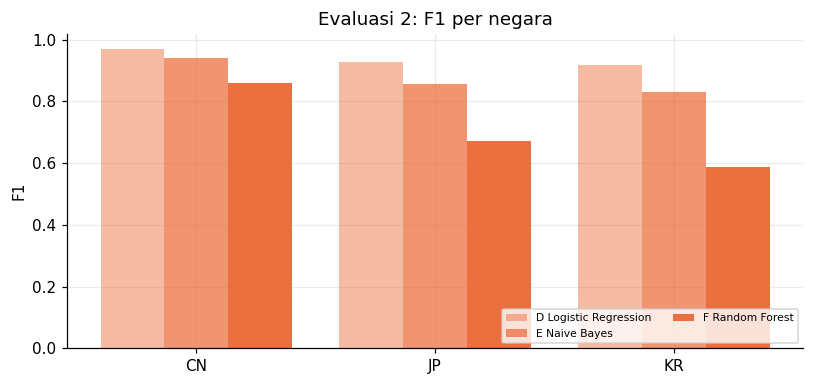

In [12]:
ml_default = {
    "D": SparkLR(family="multinomial", regParam=1.0 / n_train, maxIter=200, standardization=False),
    "E": SparkNB(smoothing=1.0, modelType="multinomial"),
    "F": SparkRF(numTrees=100, maxDepth=15, featureSubsetStrategy="sqrt", seed=SEED,
                 cacheNodeIds=True, maxMemoryInMB=1024),
}
for label, est in ml_default.items():
    _, tr_s, te_s, _ = get_spark_sets(K_OF[label])
    _, row = fit_eval_spark("E2", label, est, tr_s, te_s, k=K_OF[label])
    print(f"{label} {row['algo']:<20} k={row['k']:<6} macro-F1 {row['macro_f1']:.4f} | latih {row['fit_s']:.2f} dtk | prediksi {row['predict_s']:.2f} dtk")

print("\nEvaluasi 2 (MLlib, bawaan)")
show_stage("E2")
plot_perclass(["E2"], "Evaluasi 2: F1 per negara")

## 8. Komparasi Evaluasi 1 vs Evaluasi 2

Pasangan yang dibandingkan: A dengan D, B dengan E, C dengan F. Tabel memuat selisih skor dan rasio waktu latih (nilai di atas 1 berarti MLlib lebih lama).

,macro-F1 sklearn,macro-F1 MLlib,selisih,akurasi sklearn,akurasi MLlib,latih sklearn (dtk),latih MLlib (dtk),MLlib / sklearn (x),prediksi sklearn (dtk),prediksi MLlib (dtk)
algo,,,,,,,,,,
Logistic Regression,0.9385,0.9382,-0.0003,0.9511,0.9510,3.1712,13.4354,4.2366,0.0027,0.0880
Naive Bayes,0.8749,0.8770,0.0022,0.9020,0.9036,0.0170,0.7399,43.4967,0.0022,0.1252
Random Forest,0.8119,0.7065,-0.1054,0.8553,0.7835,3.5421,23.7575,6.7072,0.0433,1.3996


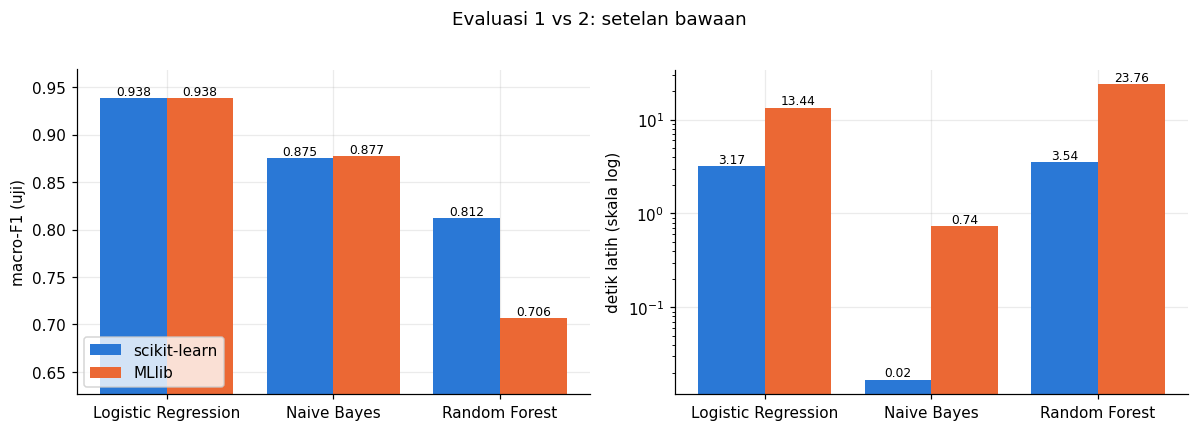

Logistic Regression  macro-F1: setara (-0.0003) | latih: MLlib lebih lambat (4.2x)
Naive Bayes          macro-F1: setara (+0.0022) | latih: MLlib lebih lambat (43.5x)
Random Forest        macro-F1: scikit-learn lebih tinggi (-0.1054) | latih: MLlib lebih lambat (6.7x)


In [13]:
def compare(stage_sk, stage_ml, title):
    sk = stage_frame(stage_sk).set_index("algo").loc[ORDER]
    ml = stage_frame(stage_ml).set_index("algo").loc[ORDER]
    table = pd.DataFrame({
        "macro-F1 sklearn": sk["macro_f1"], "macro-F1 MLlib": ml["macro_f1"],
        "selisih": ml["macro_f1"] - sk["macro_f1"],
        "akurasi sklearn": sk["accuracy"], "akurasi MLlib": ml["accuracy"],
        "latih sklearn (dtk)": sk["fit_s"], "latih MLlib (dtk)": ml["fit_s"],
        "MLlib / sklearn (x)": ml["fit_s"] / sk["fit_s"],
        "prediksi sklearn (dtk)": sk["predict_s"], "prediksi MLlib (dtk)": ml["predict_s"],
    })
    display(table.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    x = np.arange(3)
    for ax, col, ylabel, log in ((axes[0], "macro_f1", "macro-F1 (uji)", False), (axes[1], "fit_s", "detik latih (skala log)", True)):
        a, b = ax.bar(x - 0.2, sk[col], 0.4, color=SK_COLOR, label="scikit-learn"), ax.bar(x + 0.2, ml[col], 0.4, color=ML_COLOR, label="MLlib")
        ax.bar_label(a, fmt="%.2f" if log else "%.3f", fontsize=8), ax.bar_label(b, fmt="%.2f" if log else "%.3f", fontsize=8)
        ax.set_xticks(x, ORDER); ax.set_ylabel(ylabel)
        if log:
            ax.set_yscale("log")
        else:
            lo = min(sk[col].min(), ml[col].min())
            ax.set_ylim(max(0, lo - 0.08), min(1, max(sk[col].max(), ml[col].max()) + 0.03))
    axes[0].legend(loc="lower left"); fig.suptitle(title, y=1.02)
    plt.tight_layout(); plt.show()

    for algo in ORDER:
        d = ml.loc[algo, "macro_f1"] - sk.loc[algo, "macro_f1"]
        r = ml.loc[algo, "fit_s"] / sk.loc[algo, "fit_s"]
        verdict = "setara" if abs(d) < 0.005 else ("MLlib lebih tinggi" if d > 0 else "scikit-learn lebih tinggi")
        pace = "MLlib lebih lambat" if r > 1 else "MLlib lebih cepat"
        print(f"{algo:<20} macro-F1: {verdict} ({d:+.4f}) | latih: {pace} ({r:.1f}x)")


compare("E1", "E2", "Evaluasi 1 vs 2: setelan bawaan")

## 9. Tuning A, B, C di scikit-learn (Evaluasi 3)

Hyperparameter dicari dengan cross-validation 3 fold pada data latih saja, memakai nomor fold yang sama di kedua kerangka. Skor yang dikejar macro-F1. Set uji baru dipakai setelah model terbaik dipilih.

Yang disetel bukan hanya parameter model, tapi juga jumlah fitur hasil seleksi. Karena itu seleksi fitur dan model dirangkai menjadi satu pipeline (`SelectKBest` + model), dan seleksinya ikut dilatih ulang di dalam setiap fold. Dengan begitu fold validasi tidak pernah ikut menentukan fitur mana yang dipilih, dan skor cross-validation tidak optimistis.

| Model | Grid | k fitur |
|---|---|---|
| A. Logistic Regression | `C` ∈ {1, 4, 16, 64, 256} | `k` terpilih dan dua kalinya |
| B. Naive Bayes | `alpha` ∈ {0,001, 0,01, 0,1, 1} | `k` terpilih dan dua kalinya |
| C. Random Forest | `max_depth` ∈ {10, 20, 30} | `k` Random Forest saja (paling mahal) |

Grid sengaja lebih lebar dari uji awal, karena di sana nilai terbaik selalu jatuh di ujung grid (C terbesar, alpha terkecil, depth terdalam). Nilai yang menang di ujung grid berarti optimumnya mungkin di luar grid. Kedalaman berhenti di 30 karena itu batas atas `maxDepth` di MLlib.

Waktu tuning mencakup seluruh cross-validation ditambah satu refit pada seluruh data latih; waktu refit itu sendiri dilaporkan sebagai "latih final". Aturan yang sama dipakai di MLlib pada bagian 10.

In [14]:
C_GRID = [1.0, 4.0, 16.0, 64.0, 256.0]
ALPHA_GRID = [0.001, 0.01, 0.1, 1.0]
DEPTH_GRID = [10, 20, 30]
K_TUNE = sorted({k_star, K2})
K_TUNE_RF = [K_RF]


def model_params(params):
    return {name.split("__", 1)[1]: v for name, v in params.items() if name.startswith("model__")}


def tune_sklearn(label, estimator, grid, ks, grid_jobs):
    pipe = SkPipeline([("select", SelectKBest(f_classif)), ("model", estimator)])
    param_grid = {"select__k": ks, **{f"model__{name}": values for name, values in grid.items()}}
    search = GridSearchCV(pipe, param_grid, cv=PredefinedSplit(fold_tr), scoring="f1_macro",
                          n_jobs=grid_jobs, refit=True)
    with stopwatch() as t:
        search.fit(Xtr, y_tr)
    for params, score in zip(search.cv_results_["params"], search.cv_results_["mean_test_score"]):
        TUNING_LOG.append(dict(framework="scikit-learn", model=label, algo=ALGO[label], k=params["select__k"],
                               params=str(model_params(params)), cv_macro_f1=score))
    with stopwatch() as tp:
        pred = search.best_estimator_.predict(Xte)
    return record("E3", "scikit-learn", label, ALGO[label], search.refit_time_, tp["s"], y_te, pred,
                  k=search.best_params_["select__k"], tune_s=t["s"], cv_macro_f1=search.best_score_,
                  params=str(model_params(search.best_params_)),
                  **lr_iters(label, search.best_estimator_.named_steps["model"]))


tune_plan_sk = [
    ("A", LogisticRegression(max_iter=200), {"C": C_GRID}, K_TUNE, 2),
    ("B", MultinomialNB(), {"alpha": ALPHA_GRID}, K_TUNE, 2),
    ("C", RandomForestClassifier(n_estimators=100, n_jobs=CORES, random_state=SEED), {"max_depth": DEPTH_GRID}, K_TUNE_RF, 1),
]
for label, est, grid, ks, jobs in tune_plan_sk:
    row = tune_sklearn(label, est, grid, ks, jobs)
    print(f"{label} {row['algo']:<20} CV {row['cv_macro_f1']:.4f} | uji {row['macro_f1']:.4f} | k={row['k']} {row['params']} | tuning {row['tune_s']:.1f} dtk")

/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


/usr/local/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


A Logistic Regression  CV 0.9460 | uji 0.9520 | k=10000 {'C': 16.0} | tuning 53.5 dtk


B Naive Bayes          CV 0.9050 | uji 0.8999 | k=10000 {'alpha': 0.001} | tuning 1.6 dtk


C Random Forest        CV 0.8610 | uji 0.8569 | k=100 {'max_depth': 30} | tuning 37.0 dtk


Evaluasi 3 (scikit-learn, setelah tuning)


,model,algo,k,accuracy,macro_f1,weighted_f1,f1_CN,f1_JP,f1_KR,fit_s,predict_s,iters
0,A,Logistic Regression,10000,0.9617,0.9520,0.9616,0.9754,0.9427,0.9380,5.2154,0.0122,200.0
1,B,Naive Bayes,10000,0.9225,0.8999,0.9224,0.9552,0.8787,0.8659,0.1050,0.0106,NaN
2,C,Random Forest,100,0.8869,0.8569,0.8841,0.9253,0.8429,0.8025,8.3075,0.0684,NaN


,k,parameter terbaik,macro-F1 CV,macro-F1 uji (tuned),macro-F1 uji (bawaan),perubahan,waktu tuning (dtk),latih final (dtk)
algo,,,,,,,,
Logistic Regression,10000,{'C': 16.0},0.946,0.9520,0.9385,0.0135,53.5168,5.2154
Naive Bayes,10000,{'alpha': 0.001},0.905,0.8999,0.8749,0.0251,1.6362,0.1050
Random Forest,100,{'max_depth': 30},0.861,0.8569,0.8119,0.0450,37.0145,8.3075


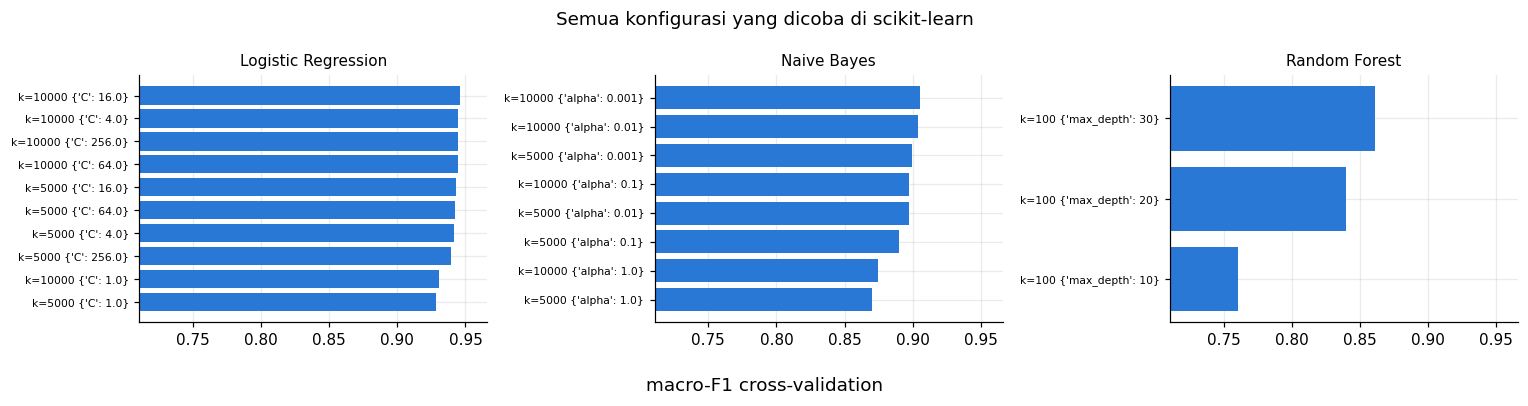

In [15]:
def tuning_summary(stage, default_stage):
    now = stage_frame(stage).set_index("algo").loc[ORDER]
    before = stage_frame(default_stage).set_index("algo").loc[ORDER]
    out = pd.DataFrame({
        "k": now["k"], "parameter terbaik": now["params"], "macro-F1 CV": now["cv_macro_f1"],
        "macro-F1 uji (tuned)": now["macro_f1"], "macro-F1 uji (bawaan)": before["macro_f1"],
        "perubahan": now["macro_f1"] - before["macro_f1"],
        "waktu tuning (dtk)": now["tune_s"], "latih final (dtk)": now["fit_s"],
    })
    display(out.round(4))


def plot_tuning(framework, title):
    log = pd.DataFrame(TUNING_LOG)
    log = log[log["framework"] == framework]
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharex=True)
    color = SK_COLOR if framework == "scikit-learn" else ML_COLOR
    for ax, algo in zip(axes, ORDER):
        part = log[log["algo"] == algo].sort_values("cv_macro_f1")
        names = [f"k={r.k} {r.params}" for r in part.itertuples()]
        ax.barh(names, part["cv_macro_f1"], color=color)
        ax.set_title(algo, fontsize=10)
        ax.tick_params(axis="y", labelsize=7)
        lo = log["cv_macro_f1"].min()
        ax.set_xlim(max(0, lo - 0.05), min(1, log["cv_macro_f1"].max() + 0.02))
    fig.suptitle(title); fig.supxlabel("macro-F1 cross-validation")
    plt.tight_layout(); plt.show()


print("Evaluasi 3 (scikit-learn, setelah tuning)")
show_stage("E3")
tuning_summary("E3", "E1")
plot_tuning("scikit-learn", "Semua konfigurasi yang dicoba di scikit-learn")

## 10. Tuning D, E, F di Spark MLlib (Evaluasi 4)

Grid dan aturan sama dengan bagian 9. Seleksi fitur (`UnivariateFeatureSelector`) dan model dirangkai dalam satu `Pipeline`, lalu dicari dengan `CrossValidator` memakai `foldCol`, jadi Spark memakai nomor fold yang sama dengan `PredefinedSplit` di scikit-learn dan seleksinya juga dilatih ulang di setiap fold. Spark tidak punya metrik macro-F1 bawaan, jadi dibuat evaluator kecil yang menghitungnya dari tabel kombinasi label dan prediksi.

Dua pengaturan dibuat setara dengan scikit-learn:

- **Paralelisme.** `GridSearchCV` di bagian 9 menjalankan dua konfigurasi sekaligus untuk Logistic Regression dan Naive Bayes (`n_jobs=2`), dan satu per satu untuk Random Forest yang sudah memakai dua core di dalamnya. `CrossValidator` diberi `parallelism` yang sama.
- **Waktu latih final.** `CrossValidator` selalu me-refit konfigurasi terbaik di akhir. Pipeline-nya diberi pencatat waktu kecil, jadi refit itu langsung dipakai untuk menilai set uji dan durasinya dilaporkan, tanpa melatih ulang sekali lagi.

`C` pada Logistic Regression diterjemahkan ke `regParam = 1 / (C × n_latih)`. Satu perbedaan kecil yang tidak bisa dihilangkan: di scikit-learn `C` dikalikan jumlah loss, sedangkan di MLlib `regParam` dikalikan rata-rata loss, jadi pada fold yang hanya dua pertiga data regularisasi MLlib setara `C` yang 1,5 kali lebih besar. Efeknya hanya memengaruhi nilai `C` terpilih, tidak memengaruhi urutan konfigurasi secara drastis.

Waktu tuning ditampilkan apa adanya. Di bagian inilah biaya terbesar MLlib biasanya muncul, karena setiap iterasi optimisasi di setiap fold adalah satu job Spark.

In [16]:
class MacroF1Evaluator(Evaluator):
    def _evaluate(self, dataset):
        tp, fp, fn = {}, {}, {}
        for r in dataset.groupBy("label", "prediction").count().collect():
            y, p, n = int(r["label"]), int(r["prediction"]), r["count"]
            if y == p:
                tp[y] = tp.get(y, 0) + n
            else:
                fn[y] = fn.get(y, 0) + n
                fp[p] = fp.get(p, 0) + n
        scores = []
        for c in set(tp) | set(fp) | set(fn):
            denom = 2 * tp.get(c, 0) + fp.get(c, 0) + fn.get(c, 0)
            scores.append(2 * tp.get(c, 0) / denom if denom else 0.0)
        return float(np.mean(scores))

    def isLargerBetter(self):
        return True


class TimedPipeline(Pipeline):
    """Pipeline yang mencatat (mulai, durasi) tiap fit. Salinan dari CrossValidator berbagi daftar yang sama,
    dan refit konfigurasi terbaik selalu dimulai paling akhir."""

    def _fit(self, dataset):
        start = time.perf_counter()
        model = super()._fit(dataset)
        self.fit_log.append((start, time.perf_counter() - start))
        return model


SPARK_NAME = {"selectionThreshold": "k", "regParam": "C", "smoothing": "alpha", "maxDepth": "max_depth"}


def readable(param_map):
    out = {}
    for p, v in param_map.items():
        name = SPARK_NAME.get(p.name, p.name)
        out[name] = int(v) if name == "k" else round(1.0 / (v * n_train), 3) if name == "C" else v
    return out


def tune_spark(label, model, add_grid, ks, parallelism):
    selector = (UnivariateFeatureSelector(featuresCol="features_all", outputCol="features", labelCol="label",
                                          selectionMode="numTopFeatures")
                .setFeatureType("continuous").setLabelType("categorical"))
    pipe = TimedPipeline(stages=[selector, model])
    pipe.fit_log = []
    grid = add_grid(ParamGridBuilder().addGrid(selector.selectionThreshold, [float(k) for k in ks]), model).build()
    cv = CrossValidator(estimator=pipe, estimatorParamMaps=grid, evaluator=MacroF1Evaluator(),
                        numFolds=3, foldCol="fold", parallelism=parallelism, seed=SEED)
    with stopwatch() as t:
        cv_model = cv.fit(train_sdf)
    for pm, score in zip(grid, cv_model.avgMetrics):
        params = readable(pm)
        k = params.pop("k")
        TUNING_LOG.append(dict(framework="MLlib", model=label, algo=ALGO[label], k=k,
                               params=str(params), cv_macro_f1=float(score)))
    i = int(np.argmax(cv_model.avgMetrics))
    best = readable(grid[i])
    best_k = best.pop("k")
    refit_s = max(pipe.fit_log)[1]
    with stopwatch() as tp:
        out = cv_model.bestModel.transform(test_sdf).select("label", "prediction").toPandas()
    return record("E4", "MLlib", label, ALGO[label], refit_s, tp["s"],
                  out["label"].astype(int), out["prediction"].astype(int),
                  k=best_k, tune_s=t["s"], cv_macro_f1=float(cv_model.avgMetrics[i]), params=str(best),
                  **lr_iters(label, cv_model.bestModel.stages[-1]))


tune_plan_ml = [
    ("D", SparkLR(family="multinomial", maxIter=200, standardization=False),
     lambda b, m: b.addGrid(m.regParam, [1.0 / (c * n_train) for c in C_GRID]), K_TUNE, 2),
    ("E", SparkNB(modelType="multinomial"),
     lambda b, m: b.addGrid(m.smoothing, ALPHA_GRID), K_TUNE, 2),
    ("F", SparkRF(numTrees=100, featureSubsetStrategy="sqrt", seed=SEED, cacheNodeIds=True, maxMemoryInMB=1024),
     lambda b, m: b.addGrid(m.maxDepth, DEPTH_GRID), K_TUNE_RF, 1),
]
for label, model, add_grid, ks, par in tune_plan_ml:
    row = tune_spark(label, model, add_grid, ks, par)
    print(f"{label} {row['algo']:<20} CV {row['cv_macro_f1']:.4f} | uji {row['macro_f1']:.4f} | k={row['k']} {row['params']} | tuning {row['tune_s']:.1f} dtk")

2026-10-14 08:18:55 | INFO     | root                   | Exception while sending command.
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/site-packages/py4j/clientserver.py", line 503, in send_command
    self.socket.sendall(command.encode("utf-8"))
ConnectionResetError: [Errno 104] Connection reset by peer

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/usr/local/lib/python3.11/site-packages/py4j/java_gateway.py", line 1038, in send_command
    response = connection.send_command(command)
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/site-packages/py4j/clientserver.py", line 506, in send_command
    raise Py4JNetworkError(
py4j.protocol.Py4JNetworkError: Error while sending


D Logistic Regression  CV 0.9455 | uji 0.9509 | k=10000 {'C': 4.0} | tuning 381.8 dtk


E Naive Bayes          CV 0.9050 | uji 0.9014 | k=10000 {'alpha': 0.001} | tuning 44.8 dtk


F Random Forest        CV 0.7441 | uji 0.7420 | k=100 {'max_depth': 30} | tuning 332.0 dtk


Evaluasi 4 (MLlib, setelah tuning)


,model,algo,k,accuracy,macro_f1,weighted_f1,f1_CN,f1_JP,f1_KR,fit_s,predict_s,iters
0,D,Logistic Regression,10000,0.9608,0.9509,0.9606,0.9749,0.9421,0.9356,18.4547,0.2138,152.0
1,E,Naive Bayes,10000,0.9238,0.9014,0.9237,0.9561,0.8790,0.8689,2.4727,0.2644,NaN
2,F,Random Forest,100,0.8042,0.7420,0.7958,0.8746,0.6917,0.6596,59.8435,4.7950,NaN


,k,parameter terbaik,macro-F1 CV,macro-F1 uji (tuned),macro-F1 uji (bawaan),perubahan,waktu tuning (dtk),latih final (dtk)
algo,,,,,,,,
Logistic Regression,10000,{'C': 4.0},0.9455,0.9509,0.9382,0.0126,381.8257,18.4547
Naive Bayes,10000,{'alpha': 0.001},0.9050,0.9014,0.8770,0.0243,44.8011,2.4727
Random Forest,100,{'max_depth': 30},0.7441,0.7420,0.7065,0.0355,331.9523,59.8435


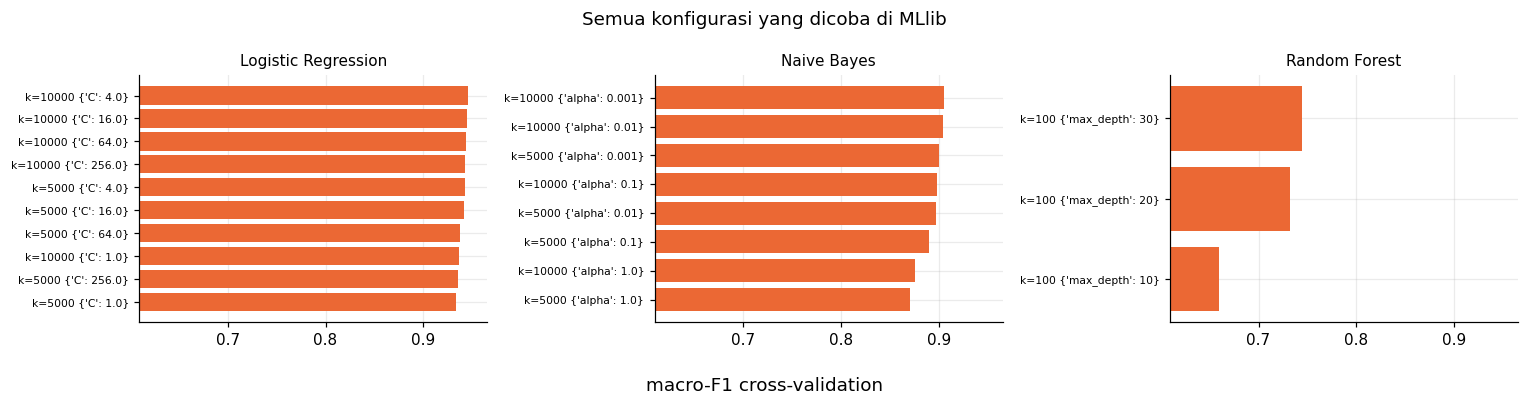

In [17]:
print("Evaluasi 4 (MLlib, setelah tuning)")
show_stage("E4")
tuning_summary("E4", "E2")
plot_tuning("MLlib", "Semua konfigurasi yang dicoba di MLlib")

## 11. Komparasi Evaluasi 3 vs Evaluasi 4

Setelah masing-masing kerangka mendapat kesempatan yang sama untuk disetel, mana yang berakhir lebih baik, dan berapa harganya? Selain tabel pasangan seperti di bagian 8, ada dua tambahan: berapa lama tuning berjalan, dan seberapa besar tuning mengubah skor dibanding setelan bawaan.

,macro-F1 sklearn,macro-F1 MLlib,selisih,akurasi sklearn,akurasi MLlib,latih sklearn (dtk),latih MLlib (dtk),MLlib / sklearn (x),prediksi sklearn (dtk),prediksi MLlib (dtk)
algo,,,,,,,,,,
Logistic Regression,0.9520,0.9509,-0.0012,0.9617,0.9608,5.2154,18.4547,3.5385,0.0122,0.2138
Naive Bayes,0.8999,0.9014,0.0014,0.9225,0.9238,0.1050,2.4727,23.5451,0.0106,0.2644
Random Forest,0.8569,0.7420,-0.1149,0.8869,0.8042,8.3075,59.8435,7.2035,0.0684,4.7950


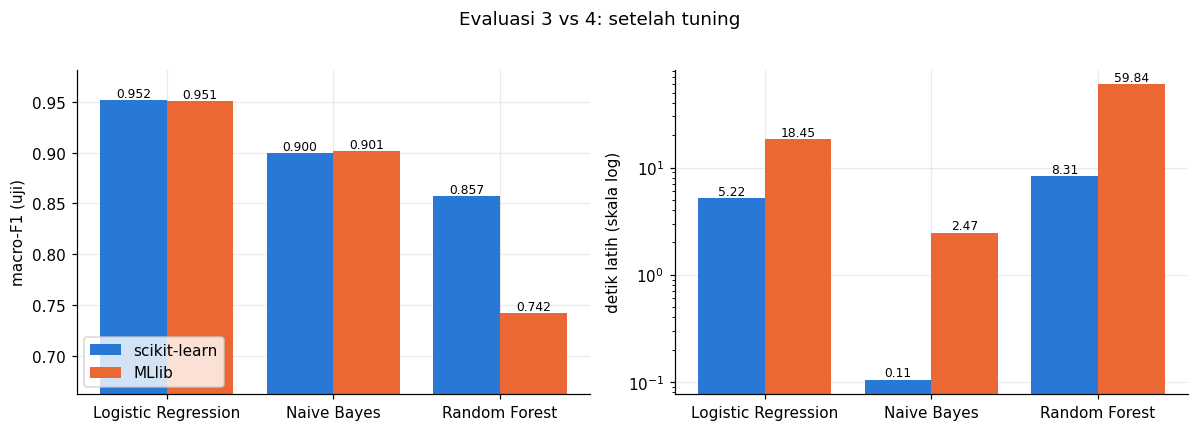

Logistic Regression  macro-F1: setara (-0.0012) | latih: MLlib lebih lambat (3.5x)
Naive Bayes          macro-F1: setara (+0.0014) | latih: MLlib lebih lambat (23.5x)
Random Forest        macro-F1: scikit-learn lebih tinggi (-0.1149) | latih: MLlib lebih lambat (7.2x)


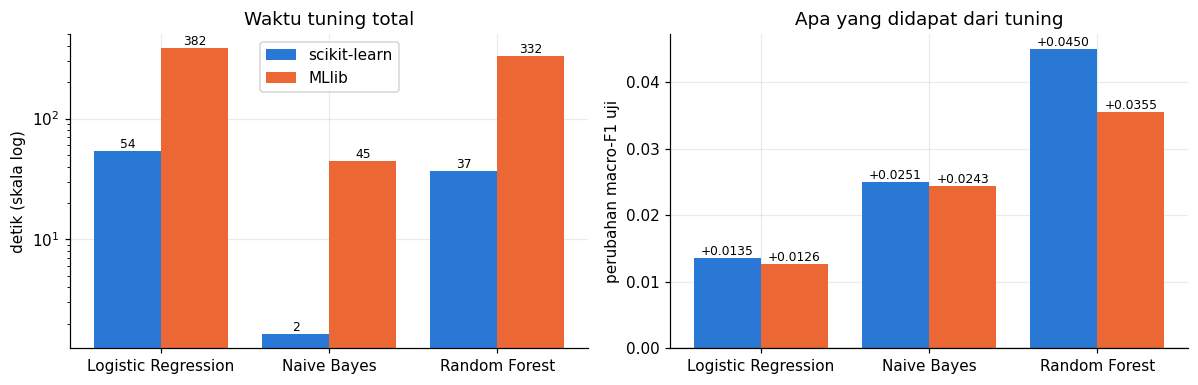

In [18]:
compare("E3", "E4", "Evaluasi 3 vs 4: setelah tuning")

tune_sk = stage_frame("E3").set_index("algo").loc[ORDER]
tune_ml = stage_frame("E4").set_index("algo").loc[ORDER]
gain_sk = tune_sk["macro_f1"] - stage_frame("E1").set_index("algo").loc[ORDER, "macro_f1"]
gain_ml = tune_ml["macro_f1"] - stage_frame("E2").set_index("algo").loc[ORDER, "macro_f1"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
x = np.arange(3)
a, b = axes[0].bar(x - 0.2, tune_sk["tune_s"], 0.4, color=SK_COLOR, label="scikit-learn"), axes[0].bar(x + 0.2, tune_ml["tune_s"], 0.4, color=ML_COLOR, label="MLlib")
axes[0].bar_label(a, fmt="%.0f", fontsize=8), axes[0].bar_label(b, fmt="%.0f", fontsize=8)
axes[0].set_yscale("log"); axes[0].set_xticks(x, ORDER); axes[0].set_ylabel("detik (skala log)")
axes[0].set_title("Waktu tuning total"); axes[0].legend()
a, b = axes[1].bar(x - 0.2, gain_sk, 0.4, color=SK_COLOR), axes[1].bar(x + 0.2, gain_ml, 0.4, color=ML_COLOR)
axes[1].bar_label(a, fmt="%+.4f", fontsize=8), axes[1].bar_label(b, fmt="%+.4f", fontsize=8)
axes[1].axhline(0, color="#52514e", lw=0.8); axes[1].set_xticks(x, ORDER)
axes[1].set_ylabel("perubahan macro-F1 uji"); axes[1].set_title("Apa yang didapat dari tuning")
plt.tight_layout(); plt.show()

## 12. Komparasi keseluruhan

Bagian terakhir menjawab pertanyaan awal: kalau satu tugas yang sama dikerjakan di dua kerangka, apa bedanya dalam kecepatan, performa, dan perilaku saat datanya membesar?

### 12.1 Performa: enam model, dua kondisi

bawaan   tuned  perubahan
Logistic Regression scikit-learn  0.9385  0.9520     0.0135
                    MLlib         0.9382  0.9509     0.0126
Naive Bayes         scikit-learn  0.8749  0.8999     0.0251
                    MLlib         0.8770  0.9014     0.0243
Random Forest       scikit-learn  0.8119  0.8569     0.0450
                    MLlib         0.7065  0.7420     0.0355

Skor uji tertinggi: model A (Logistic Regression, scikit-learn), macro-F1 0.9520, akurasi 0.9617


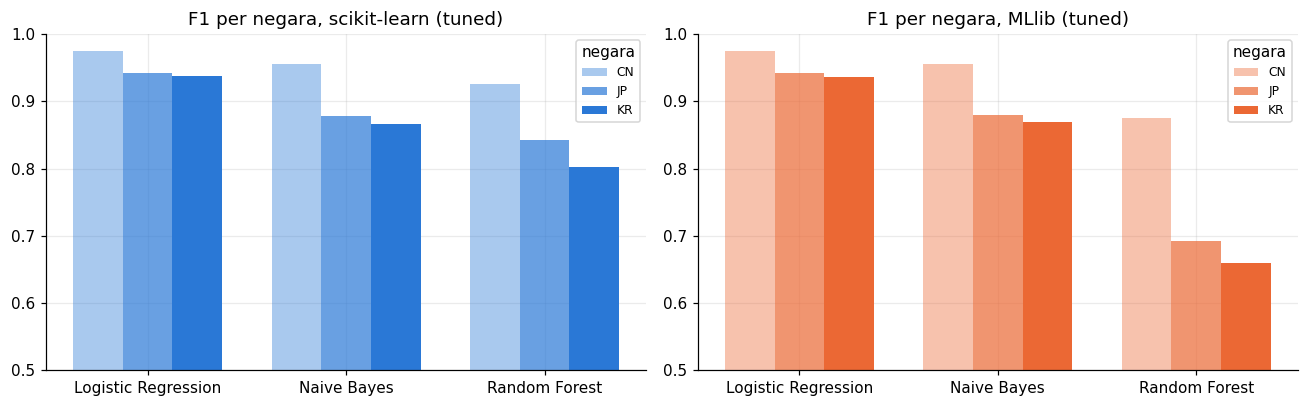

In [19]:
res = pd.DataFrame(RESULTS)
perf = res.pivot_table(index=["algo", "framework"], columns="stage", values="macro_f1").reindex(
    pd.MultiIndex.from_product([ORDER, ["scikit-learn", "MLlib"]]))
perf.columns = [{"E1": "bawaan (E1)", "E2": "bawaan (E2)", "E3": "tuned (E3)", "E4": "tuned (E4)"}[c] for c in perf.columns]
perf["bawaan"] = perf[["bawaan (E1)", "bawaan (E2)"]].bfill(axis=1).iloc[:, 0]
perf["tuned"] = perf[["tuned (E3)", "tuned (E4)"]].bfill(axis=1).iloc[:, 0]
perf = perf[["bawaan", "tuned"]]
perf["perubahan"] = perf["tuned"] - perf["bawaan"]
display(perf.round(4))

best_row = res[res["stage"].isin(["E3", "E4"])].sort_values("macro_f1", ascending=False).iloc[0]
print(f"Skor uji tertinggi: model {best_row['model']} ({best_row['algo']}, {best_row['framework']}), "
      f"macro-F1 {best_row['macro_f1']:.4f}, akurasi {best_row['accuracy']:.4f}")

tuned = res[res["stage"].isin(["E3", "E4"])].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, framework, color in ((axes[0], "scikit-learn", SK_COLOR), (axes[1], "MLlib", ML_COLOR)):
    part = tuned[tuned["framework"] == framework].set_index("algo").loc[ORDER]
    width = 0.25
    for i, c in enumerate(CLASSES):
        ax.bar(np.arange(3) + (i - 1) * width, part[f"f1_{c}"], width, label=c, color=color, alpha=0.4 + 0.3 * i)
    ax.set_xticks(np.arange(3), ORDER); ax.set_ylim(0.5, 1.0)
    ax.set_title(f"F1 per negara, {framework} (tuned)"); ax.legend(title="negara", fontsize=8)
plt.tight_layout(); plt.show()

### 12.2 Kecepatan: dari fitur mentah sampai model siap

Tabel ini menjumlahkan tiap tahap per kerangka. Kurva pemilihan `k` di bagian 5 tidak ikut dihitung karena itu eksplorasi satu kali yang tidak akan diulang di pipeline produksi.

Cara membacanya: kolom rasio di atas 1 berarti MLlib lebih lama. Ingat kondisinya: dua core, satu mesin, data sekitar 39 ribu baris. Ini jauh di bawah ukuran yang membuat Spark seharusnya unggul, jadi hasilnya tidak boleh dibaca sebagai penilaian umum atas Spark.

,scikit-learn,MLlib,MLlib / sklearn (x)
bangun fitur,10.27,28.15,2.74
seleksi fitur,0.16,2.46,15.66
latih 3 model (bawaan),6.73,37.93,5.64
prediksi 3 model (bawaan),0.05,1.61,33.47
tuning 3 model,92.17,758.58,8.23
TOTAL,109.37,828.73,7.58


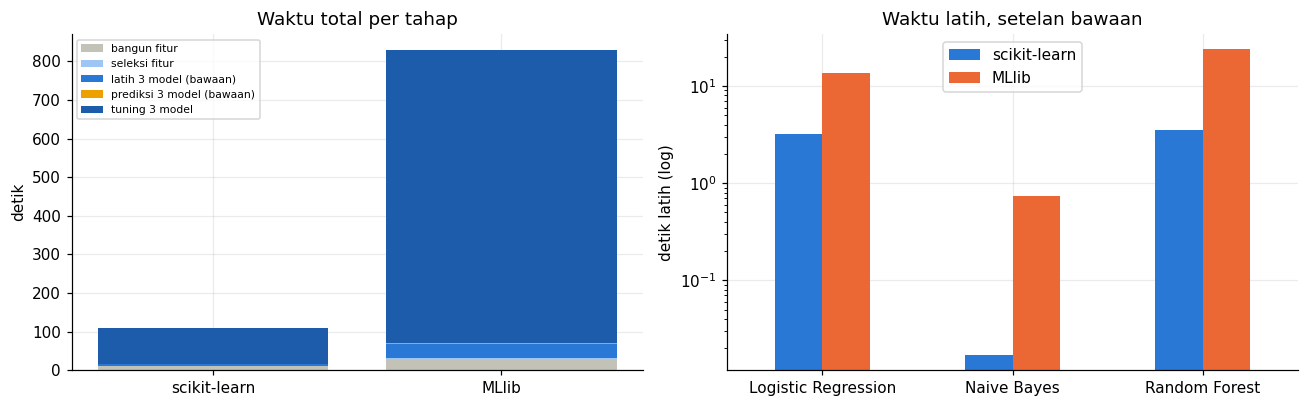

In [20]:
def total(stage, col):
    return float(stage_frame(stage)[col].sum())

speed = pd.DataFrame({
    "scikit-learn": {
        "bangun fitur": TIMING["prep_sk"], "seleksi fitur": TIMING["select_sk"],
        "latih 3 model (bawaan)": total("E1", "fit_s"), "prediksi 3 model (bawaan)": total("E1", "predict_s"),
        "tuning 3 model": total("E3", "tune_s"),
    },
    "MLlib": {
        "bangun fitur": TIMING["prep_ml"], "seleksi fitur": TIMING["select_ml"],
        "latih 3 model (bawaan)": total("E2", "fit_s"), "prediksi 3 model (bawaan)": total("E2", "predict_s"),
        "tuning 3 model": total("E4", "tune_s"),
    },
})
speed.loc["TOTAL"] = speed.sum()
speed["MLlib / sklearn (x)"] = speed["MLlib"] / speed["scikit-learn"]
display(speed.round(2))

parts = speed.drop(index="TOTAL")[["scikit-learn", "MLlib"]]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bottom = np.zeros(2)
shades = ["#c3c2b7", "#9ec5f4", "#2a78d6", "#eda100", "#1c5cab"]
for (stage_name, vals), shade in zip(parts.iterrows(), shades):
    axes[0].bar(["scikit-learn", "MLlib"], vals.values, bottom=bottom, label=stage_name, color=shade)
    bottom += vals.values
axes[0].set_ylabel("detik"); axes[0].set_title("Waktu total per tahap"); axes[0].legend(fontsize=7)

fit_cmp = pd.DataFrame({"scikit-learn": stage_frame("E1").set_index("algo").loc[ORDER, "fit_s"],
                        "MLlib": stage_frame("E2").set_index("algo").loc[ORDER, "fit_s"]})
fit_cmp.plot.bar(ax=axes[1], color=[SK_COLOR, ML_COLOR], rot=0, logy=True)
axes[1].set_ylabel("detik latih (log)"); axes[1].set_title("Waktu latih, setelan bawaan"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

### 12.3 Perilaku saat data membesar

Satu eksperimen kecil untuk melihat ke mana kurvanya menuju: Logistic Regression dengan setelan bawaan dilatih pada 25%, 50%, 100% data latih, lalu pada data yang digandakan 2 dan 4 kali. Penggandaan hanya dipakai untuk mengukur waktu (baris yang sama muncul berulang), jadi skornya tidak dilaporkan. Di scikit-learn waktu yang diukur adalah `fit`; di MLlib juga `fit`, setelah data sudah di-cache di cluster.

Kedua kerangka berhenti dengan kriteria berbeda, jadi jumlah iterasinya tidak sama. Selain rasio waktu total, dicatat juga rasio waktu per iterasi, yang lebih jujur untuk membandingkan kecepatan mesinnya.

0.25x |   7,923 baris | sklearn    0.6s (100 iter) | MLlib    7.0s (200 iter) | rasio 12.2x, per iterasi 6.1x


 0.5x |  15,749 baris | sklearn    1.3s (118 iter) | MLlib    8.1s (193 iter) | rasio 6.4x, per iterasi 3.9x


   1x |  31,186 baris | sklearn    3.0s (150 iter) | MLlib    7.9s (137 iter) | rasio 2.6x, per iterasi 2.8x


   2x |  62,372 baris | sklearn    6.2s (159 iter) | MLlib   11.6s (125 iter) | rasio 1.9x, per iterasi 2.4x


   4x | 124,744 baris | sklearn   15.2s (200 iter) | MLlib   21.7s (133 iter) | rasio 1.4x, per iterasi 2.1x


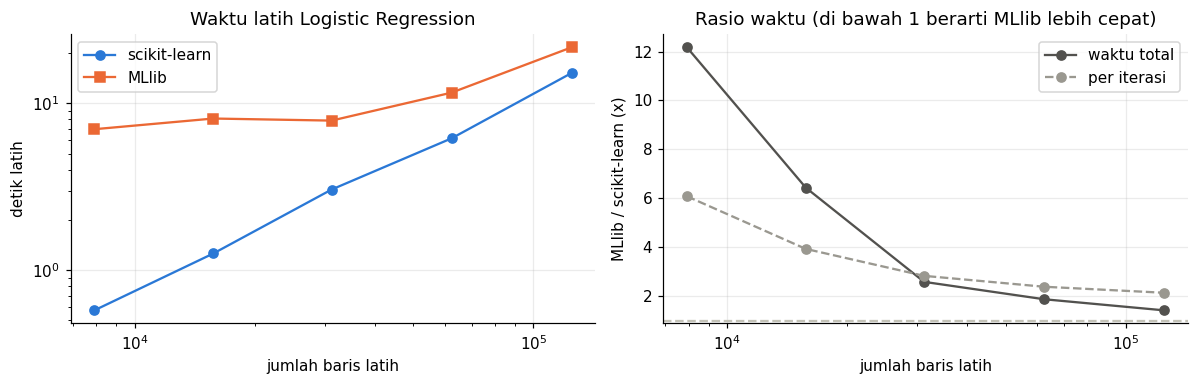

In [21]:
MULTS = [0.5, 1, 2] if SMOKE else [0.25, 0.5, 1, 2, 4]
Xa_scale, _ = get_sk_sets(k_star)
_, tr_scale, _, _ = get_spark_sets(k_star)
rng = np.random.default_rng(SEED)
rows = []
for m in MULTS:
    if m < 1:
        pick = np.sort(rng.choice(Xa_scale.shape[0], int(Xa_scale.shape[0] * m), replace=False))
        Xm, ym = Xa_scale[pick], y_tr[pick]
        sdf_m = tr_scale.sample(False, m, SEED)
    else:
        reps = int(m)
        Xm, ym = sparse.vstack([Xa_scale] * reps).tocsr(), np.tile(y_tr, reps)
        sdf_m = reduce(lambda a, b: a.union(b), [tr_scale] * reps)
    sdf_m = sdf_m.repartition(CORES).cache()
    n_rows = sdf_m.count()

    with stopwatch() as t_sk:
        sk_m = LogisticRegression(C=1.0, max_iter=200).fit(Xm, ym)
    with stopwatch() as t_ml:
        ml_m = SparkLR(family="multinomial", regParam=1.0 / n_rows, maxIter=200, standardization=False).fit(sdf_m)
    sdf_m.unpersist()
    it_sk, it_ml = iterations(sk_m), iterations(ml_m)
    rows.append(dict(kali_data=m, baris=n_rows, sklearn_s=t_sk["s"], mllib_s=t_ml["s"], rasio=t_ml["s"] / t_sk["s"],
                     iter_sklearn=it_sk, iter_mllib=it_ml,
                     rasio_per_iterasi=(t_ml["s"] / it_ml) / (t_sk["s"] / it_sk)))
    print(f"{m:>4}x | {n_rows:>7,} baris | sklearn {t_sk['s']:6.1f}s ({it_sk} iter) | "
          f"MLlib {t_ml['s']:6.1f}s ({it_ml} iter) | rasio {t_ml['s'] / t_sk['s']:.1f}x, per iterasi {rows[-1]['rasio_per_iterasi']:.1f}x")

scaling = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(scaling["baris"], scaling["sklearn_s"], "o-", color=SK_COLOR, label="scikit-learn")
axes[0].plot(scaling["baris"], scaling["mllib_s"], "s-", color=ML_COLOR, label="MLlib")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("jumlah baris latih"); axes[0].set_ylabel("detik latih"); axes[0].legend()
axes[0].set_title("Waktu latih Logistic Regression")
axes[1].plot(scaling["baris"], scaling["rasio"], "o-", color="#52514e", label="waktu total")
axes[1].plot(scaling["baris"], scaling["rasio_per_iterasi"], "o--", color="#9a9890", label="per iterasi")
axes[1].axhline(1, color="#c3c2b7", ls="--"); axes[1].set_xscale("log")
axes[1].set_xlabel("jumlah baris latih"); axes[1].set_ylabel("MLlib / scikit-learn (x)")
axes[1].set_title("Rasio waktu (di bawah 1 berarti MLlib lebih cepat)"); axes[1].legend()
plt.tight_layout(); plt.show()

### 12.4 Kesalahan yang tersisa

Satu pertanyaan terakhir yang tidak terjawab dari angka rata-rata: model yang tuned itu salah di mana? Matriks kebingungan untuk model terbaik di tiap kerangka.

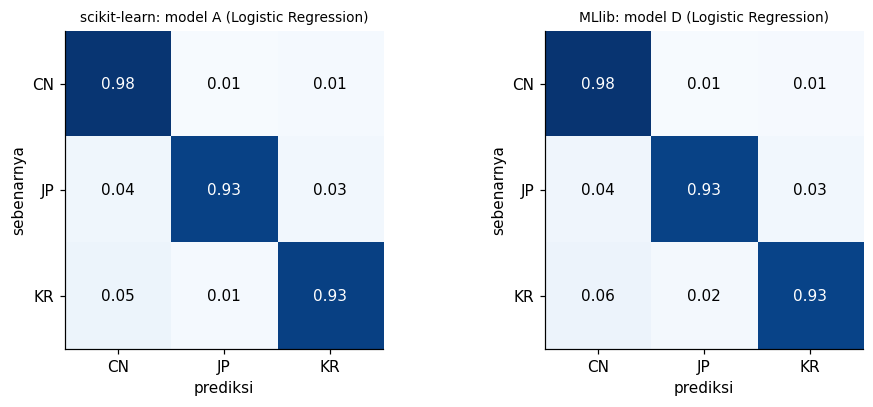

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, framework in zip(axes, ["scikit-learn", "MLlib"]):
    top = tuned[tuned["framework"] == framework].sort_values("macro_f1", ascending=False).iloc[0]
    y_true, y_pred = PRED[(top["stage"], top["model"])]
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(3), CLASSES); ax.set_yticks(range(3), CLASSES)
    ax.set_xlabel("prediksi"); ax.set_ylabel("sebenarnya"); ax.grid(False)
    ax.set_title(f"{framework}: model {top['model']} ({top['algo']})", fontsize=9)
plt.tight_layout(); plt.show()

### 12.5 Ringkasan otomatis dari angka run ini

Sel di bawah menyusun kesimpulan langsung dari hasil yang baru saja dihitung, jadi kalimatnya ikut berubah kalau notebook dijalankan lagi dengan data atau cluster yang berbeda. Penjelasan yang lebih panjang ada di sel catatan sesudahnya.

In [23]:
d_def = stage_frame("E2").set_index("algo").loc[ORDER, "macro_f1"] - stage_frame("E1").set_index("algo").loc[ORDER, "macro_f1"]
d_tun = stage_frame("E4").set_index("algo").loc[ORDER, "macro_f1"] - stage_frame("E3").set_index("algo").loc[ORDER, "macro_f1"]
ratio_fit = (stage_frame("E2").set_index("algo").loc[ORDER, "fit_s"] / stage_frame("E1").set_index("algo").loc[ORDER, "fit_s"])
total_ratio = speed.loc["TOTAL", "MLlib"] / speed.loc["TOTAL", "scikit-learn"]
caught_up = scaling[scaling["rasio"] < 1]

lines = [
    f"Performa: selisih macro-F1 MLlib minus scikit-learn pada setelan bawaan rata-rata {d_def.mean():+.4f}, "
    f"setelah tuning rata-rata {d_tun.mean():+.4f}. Selisih terbesar ada di {d_def.abs().idxmax()} (bawaan) "
    f"dan {d_tun.abs().idxmax()} (tuned).",
    f"Model terbaik secara keseluruhan: {best_row['algo']} di {best_row['framework']} (macro-F1 {best_row['macro_f1']:.4f}).",
    f"Kecepatan latih bawaan: MLlib {ratio_fit.min():.1f}x sampai {ratio_fit.max():.1f}x waktu scikit-learn per model; "
    f"seluruh pipeline MLlib memakan {total_ratio:.1f}x waktu scikit-learn.",
    f"Tuning: macro-F1 uji berubah rata-rata {(stage_frame('E3')['macro_f1'].values - stage_frame('E1')['macro_f1'].values).mean():+.4f} "
    f"di scikit-learn dan {(stage_frame('E4')['macro_f1'].values - stage_frame('E2')['macro_f1'].values).mean():+.4f} di MLlib.",
    f"Per iterasi L-BFGS MLlib {scaling['rasio_per_iterasi'].min():.1f}x sampai {scaling['rasio_per_iterasi'].max():.1f}x lebih lambat; "
    f"pada data latih penuh scikit-learn berhenti setelah {int(scaling.loc[scaling['kali_data'] == 1, 'iter_sklearn'].iloc[0])} iterasi "
    f"dan MLlib setelah {int(scaling.loc[scaling['kali_data'] == 1, 'iter_mllib'].iloc[0])}.",
    (f"Skala data: MLlib mulai lebih cepat dari scikit-learn pada {caught_up.iloc[0]['baris']:,.0f} baris "
     f"(rasio {caught_up.iloc[0]['rasio']:.2f}x)." if len(caught_up) else
     f"Skala data: sampai {scaling['baris'].max():,.0f} baris MLlib belum menyusul scikit-learn "
     f"(rasio terkecil {scaling['rasio'].min():.1f}x)."),
]
for line in lines:
    print("-", line)

- Performa: selisih macro-F1 MLlib minus scikit-learn pada setelan bawaan rata-rata -0.0345, setelah tuning rata-rata -0.0382. Selisih terbesar ada di Random Forest (bawaan) dan Random Forest (tuned).
- Model terbaik secara keseluruhan: Logistic Regression di scikit-learn (macro-F1 0.9520).
- Kecepatan latih bawaan: MLlib 4.2x sampai 43.5x waktu scikit-learn per model; seluruh pipeline MLlib memakan 7.6x waktu scikit-learn.
- Tuning: macro-F1 uji berubah rata-rata +0.0279 di scikit-learn dan +0.0241 di MLlib.
- Per iterasi L-BFGS MLlib 2.1x sampai 6.1x lebih lambat; pada data latih penuh scikit-learn berhenti setelah 150 iterasi dan MLlib setelah 137.
- Skala data: sampai 124,744 baris MLlib belum menyusul scikit-learn (rasio terkecil 1.4x).


### 12.6 Catatan interpretasi

Angka di catatan ini dari run penuh 14 Oktober 2026 (31.186 novel latih, 7.797 uji, worker 2 core). Kalau notebook dijalankan ulang, ringkasan otomatis di atas yang mengikuti angka terbaru; catatan ini tidak.

**Performa: dua dari tiga pasangan setara.** Logistic Regression dan Naive Bayes memberi macro-F1 yang hampir sama di kedua kerangka, baik dengan setelan bawaan (0,9385 vs 0,9382; 0,8749 vs 0,8770) maupun setelah tuning (0,9520 vs 0,9509; 0,8999 vs 0,9014). Selisih sekecil itu masih dalam rentang yang wajar dari perbedaan implementasi (rumus IDF, binning kuantil, kriteria berhenti L-BFGS). Untuk model linear dan Naive Bayes, memilih kerangka tidak mengubah kualitas.

**Random Forest adalah pengecualian.** MLlib tertinggal jauh: 0,7065 vs 0,8119 pada setelan bawaan, dan 0,7420 vs 0,8569 setelah tuning, dengan jumlah pohon, kedalaman, `k`, dan aturan sampling fitur yang sama. Tersangka utamanya cara MLlib memecah fitur kontinu ke 32 bin kuantil yang dihitung dari sampel. Pada fitur TF-IDF yang sebagian besar nol, bin itu kasar, sedangkan scikit-learn mencari titik potong tepat. Ini dugaan yang belum diuji di notebook ini; menaikkan `maxBins` adalah percobaan berikutnya yang paling murah.

**Random Forest memang lemah untuk tugas ini.** Kurvanya menurun saat fitur ditambah (0,816 di 100 fitur, 0,774 di 3.000), kebalikan dari Logistic Regression yang terus naik sampai 5.000 fitur. Model pohon dengan √k fitur per percabangan tidak cocok untuk ribuan potongan teks yang jarang muncul. Model terbaik keseluruhan tetap Logistic Regression scikit-learn (macro-F1 0,9520, akurasi 0,9617). KR paling sulit dikenali di semua model (F1 0,938 di model terbaik), kemungkinan karena tema romansa fantasi ala Korea juga banyak dipakai novel CN (dugaan, belum diuji).

**Tuning layak dilakukan, dan grid harus cukup lebar.** Tuning menaikkan macro-F1 rata-rata 0,028 di scikit-learn dan 0,024 di MLlib, sebagian besar dari `C` yang lebih besar, `alpha` yang lebih kecil, dan pohon yang lebih dalam. `C` terbaik (16 di scikit-learn, 4 di MLlib) kini berada di dalam grid. Perbedaan `C` terpilih sesuai dengan catatan di bagian 10: di dalam fold, regularisasi MLlib setara `C` yang 1,5 kali lebih besar. `alpha` terbaik masih di ujung grid (0,001), tapi selisih skornya dengan 0,01 di bawah 0,002, dan `max_depth` 30 adalah batas atas MLlib.

**Kecepatan: MLlib lebih lambat, tapi celahnya menyempit saat data membesar.** Seluruh pipeline MLlib memakan 7,6 kali waktu scikit-learn. Biaya terbesar ada di tuning: 382 dtk vs 54 dtk untuk Logistic Regression, dan 332 dtk vs 37 dtk untuk Random Forest. Pada eksperimen skala, rasio waktu latih Logistic Regression turun dari 12,2x (7.923 baris) menjadi 1,4x (124.744 baris), dan rasio per iterasi dari 6,1x menjadi 2,1x. Penyebabnya, setiap iterasi MLlib membayar ongkos tetap untuk menjadwalkan job Spark. Ongkos itu dominan saat data kecil dan makin tidak berarti saat data besar. Dengan tren ini, MLlib kemungkinan menyusul di beberapa ratus ribu baris pada cluster yang sama, atau lebih cepat lagi bila worker ditambah. Itu ekstrapolasi, bukan hasil ukur.

**Kesimpulan untuk proyek ini.** Pada ukuran katalog sekarang (sekitar 39 ribu novel), scikit-learn lebih cepat dengan kualitas setara untuk model linear, jadi tetap dipakai untuk pelatihan sehari-hari. MLlib layak dipakai ketika data latih tidak lagi muat di memori satu mesin. Hindari Random Forest MLlib untuk fitur teks yang jarang.

## 13. Simpan hasil dan tutup sesi

Semua angka di atas disimpan ke `Doc/generated/sklearn_vs_mllib.json` supaya bisa dipakai di laporan tanpa menjalankan ulang (mode uji cepat menulis ke berkas `_smoke` agar tidak menimpa hasil sungguhan). Sesi Spark ditutup di akhir supaya core dikembalikan ke cluster.

In [24]:
payload = {
    "generated_at": time.strftime("%Y-%m-%dT%H:%M:%S"),
    "smoke": SMOKE,
    "setup": {
        "rows": len(pdf), "train": len(pdf_tr), "test": len(pdf_te), "classes": CLASSES, "cores": CORES,
        "k_star": k_star, "k_rf": K_RF, "k_tune": K_TUNE, "dim_sklearn": int(Xtr.shape[1]), "dim_mllib": int(dim_sp),
        "spark": spark.version,
    },
    "timing": TIMING,
    "feature_selection_curve": curve.drop(columns="x").to_dict("records"),
    "feature_selection_curve_rf": curve_rf.drop(columns="x").to_dict("records"),
    "results": RESULTS,
    "tuning_log": TUNING_LOG,
    "scaling": scaling.to_dict("records"),
}
out_path = Path(settings.paths.doc_dir) / "generated" / ("sklearn_vs_mllib_smoke.json" if SMOKE else "sklearn_vs_mllib.json")
out_path.write_text(json.dumps(payload, indent=2, ensure_ascii=False,
                               default=lambda o: o.item() if hasattr(o, "item") else str(o)), encoding="utf-8")
print("Hasil disimpan ke", out_path)

spark.stop()
print("Sesi Spark ditutup.")

Hasil disimpan ke /opt/project/Doc/generated/sklearn_vs_mllib.json


Sesi Spark ditutup.
